# Media Mix Modeling (MMM) Tutorial

This notebook demonstrates how to build and analyze a Marketing Mix Model using PyMC Marketing.

## Prepare Notebook

Let's import the necessary libraries:

In [1]:
# environment setup
import sys
sys.path.insert(0, ".")
import yaml
import logging
from typing import Dict, Any


# pymc-labs imports
# pymc_marketing upgrade imports
from pymc_marketing.mmm.mmm import MMM
from pymc_extras.prior import Prior
from pymc_extras.prior import VariableFactory
from pymc_marketing.mmm.components.adstock import GeometricAdstock
from pymc_marketing.mmm.components.saturation import LogisticSaturation
from pymc_marketing.mmm.components.adstock import NoAdstock
from pymc_marketing.mmm.components.saturation import NoSaturation

# helper libraries
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytensor 
import jax 
import pytensor.tensor as pt
import numpyro 
import pandas as pd


# Import custom functions

from b2b_src.ETL import load_and_standardize_data
from b2b_src.Prior_upgrade import PerChannelDistributionFactory
from b2b_src.contributions import compare_predictions
from b2b_src.contributions import get_individual_contributions
from b2b_src.contributions import calculate_roas
from b2b_src.contributions import calculate_roas_time_series
from b2b_src.visual_tools import plot_sales_and_channels
from b2b_src.visual_tools import plot_all_contributions
from b2b_src.visual_tools import plot_roas_analysis
from b2b_src.visual_tools import plot_roas_time_series
from b2b_src.visual_tools import plot_prior_predictive_with_log_reversion
from b2b_src.visual_tools import plot_posterior_predictive_with_log_reversion
from b2b_src.visual_tools import plot_response_curves
from b2b_src.contributions import analyze_revenue_vs_spend_levels
from b2b_src.contributions import calculate_marginal_roas
from b2b_src.utils import plot_trace_with_channel_names      
from b2b_src.utils import summary_with_channel_names         
from pymc_marketing.logging_config import setup_logging


# Import utils functions
from b2b_src.utils import create_adstock_from_config
from b2b_src.utils import create_saturation_from_config

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Read config file

In [2]:
# Load configuration from YAML file
with open("mmm_config_simu.yml", "r") as f:
    config = yaml.safe_load(f)

# Create config objects

In [3]:
# ============================================================================
# PARSE CONFIG AND BUILD VARIABLES FROM INLINE STRUCTURE
# ============================================================================
# Setup logging
setup_logging('mmm_config_simu.yml')
# Parse inline channel definitions
channels = config['data']['columns']['channels']

# Extract channel names and mappings
channel_cols = [ch['name'] for ch in channels]
spend_mapping = {ch['name']: ch['spend_column'] for ch in channels}
paid_channel_names = [ch['name'] for ch in channels if ch['type'] == 'paid']
unpaid_channel_names = [ch['name'] for ch in channels if ch['type'] == 'unpaid']

print("=" * 70)
print("CHANNEL CONFIGURATION (from inline config)")
print("=" * 70)
print(f"\nAll channels: {channel_cols}")
print(f"Paid channels: {paid_channel_names}")
print(f"Unpaid channels: {unpaid_channel_names}")
print(f"\nSpend mapping: {spend_mapping}")

# Parse inline control definitions
controls = config['data']['columns']['controls']
control_cols = [ctrl['name'] for ctrl in controls]

print(f"\nControl columns: {control_cols}")
print("=" * 70)

# Apply visualization configuration from config file
viz_config = config['visualization']
az.style.use(viz_config['style'])
plt.rcParams["figure.figsize"] = viz_config['figure']['figsize']
plt.rcParams["figure.dpi"] = viz_config['figure']['dpi']
%config InlineBackend.figure_format = viz_config['backend']['format']
%load_ext autoreload
%autoreload 2

progress_bar = config['sampling']['progressbar']

# Set random seed for reproducibility from config
seed = config['sampling']['random_seed']

# Get logging configuration from config
log_config = config['logging']

# Get model configuration
model_config = config['model']
adstock_config = model_config['adstock']
saturation_config = model_config['saturation']

# Get date column from config
date_col = config['data']['columns']['date_column']

# Get yearly seasonality setting from config
yearly_seasonality = model_config['seasonality']['yearly_seasonality']


# Baseline components from config
baseline_components = config['analysis']['baseline_components']

# Get log transformation variables from config
log_transform_vars = model_config.get('log_transformation', [])

# Get scaling and intercept settings from config
apply_scaling = model_config.get('apply_scaling', True)
fit_intercept = model_config.get('fit_intercept', True)

# Generate prior predictive samples using config
prior_samples = config['sampling']['prior_predictive']['samples']

CHANNEL CONFIGURATION (from inline config)

All channels: ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits', 'MV_Paid_1_visits', 'MV_Paid_2_visits']
Paid channels: ['MV_Paid_1_visits', 'MV_Paid_2_visits']
Unpaid channels: ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits']

Spend mapping: {'MV_Unpaid_1_visits': 'MV_Unpaid_1_visits', 'MV_Unpaid_2_visits': 'MV_Unpaid_2_visits', 'MV_Paid_1_visits': 'MV_Paid_1_Spend', 'MV_Paid_2_visits': 'MV_Paid_2_Spend'}

Control columns: ['Control_1', 'Control_2', 'Holiday_Christmas']


## Enhanced Logging

The MMM classes now include comprehensive logging to help you track the modeling process. Let's configure logging to see detailed information about what's happening during model operations:

In [4]:
# # DEBUG: Check logging state before configuration
# root = logging.getLogger()
# print(f"=== BEFORE configuring logging ===")
# print(f"Root logger handlers: {len(root.handlers)}")
# print(f"Root handlers: {root.handlers}")
# for i, handler in enumerate(root.handlers):
#     print(f"  Handler {i}: {handler}")



# # Clear any existing root handlers to start fresh
# # This is essential in Jupyter notebooks to prevent handler accumulation
# root_logger = logging.getLogger()
# if root_logger.hasHandlers():
#     root_logger.handlers.clear()

# # Apply base configuration to ROOT logger
# logging.basicConfig(
#     level=getattr(logging, log_config['level']),
#     format=log_config['format'],
#     datefmt=log_config['date_format']
# )

# # Configure the MMM logger level from config
# # The MMM logger will propagate to root, so it will use the root handler
# mmm_logger = logging.getLogger(log_config['mmm_logger']['name'])
# mmm_logger.setLevel(getattr(logging, log_config['mmm_logger']['level']))

# # Optionally quiet very chatty external loggers if needed
# # Avoid duplicate/verbose logs from PyMC internal forward sampler
# logging.getLogger("pymc.sampling.forward").propagate = False

# print("Logging configured! Now all MMM operations will show detailed process information.")





# Set random seed 

In [5]:
# Set random seed for reproducibility from config
rng = np.random.default_rng(seed=seed)
print(f"Random seed set to: {seed}")

Random seed set to: 327


# Load Data


In [6]:
data = load_and_standardize_data(config)

✓ Renamed target column 'KPI' → 'y'
Data shape: (140, 17)


,week_start_date,Intercept,Trend,Fourier_sin_1,Fourier_cos_1,Fourier_sin_2,Fourier_cos_2,Holiday_Christmas,Control_1,Control_2,MV_Unpaid_1_visits,MV_Unpaid_2_visits,MV_Paid_1_Spend,MV_Paid_1_visits,MV_Paid_2_Spend,MV_Paid_2_visits,y
0,2023-01-28,1,1,0.000000,1.000000,0.000000,1.000000,0,0.496714,116.381149,100.000000,100.000000,917.624607,18165.940444,500.000000,3843.416917,105062.901830
1,2023-02-04,1,2,0.120537,0.992709,0.239316,0.970942,0,0.138264,112.424026,100.000000,100.000000,931.255734,18494.753023,500.000000,4008.569354,100154.130052
2,2023-02-11,1,3,0.239316,0.970942,0.464723,0.885456,0,0.647689,110.592654,100.000000,100.000000,971.042319,17738.157316,507.026442,2928.068871,108741.462944
3,2023-02-18,1,4,0.354605,0.935016,0.663123,0.748511,0,1.523030,106.106006,145.219227,133.585944,1165.221364,18982.038773,551.433524,4546.707517,118425.126125
4,2023-02-25,1,5,0.464723,0.885456,0.822984,0.568065,0,0.234153,104.627937,299.298986,131.501936,1030.911018,18319.456422,507.458134,2505.155811,102655.089414


# Visualize data

c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:100: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


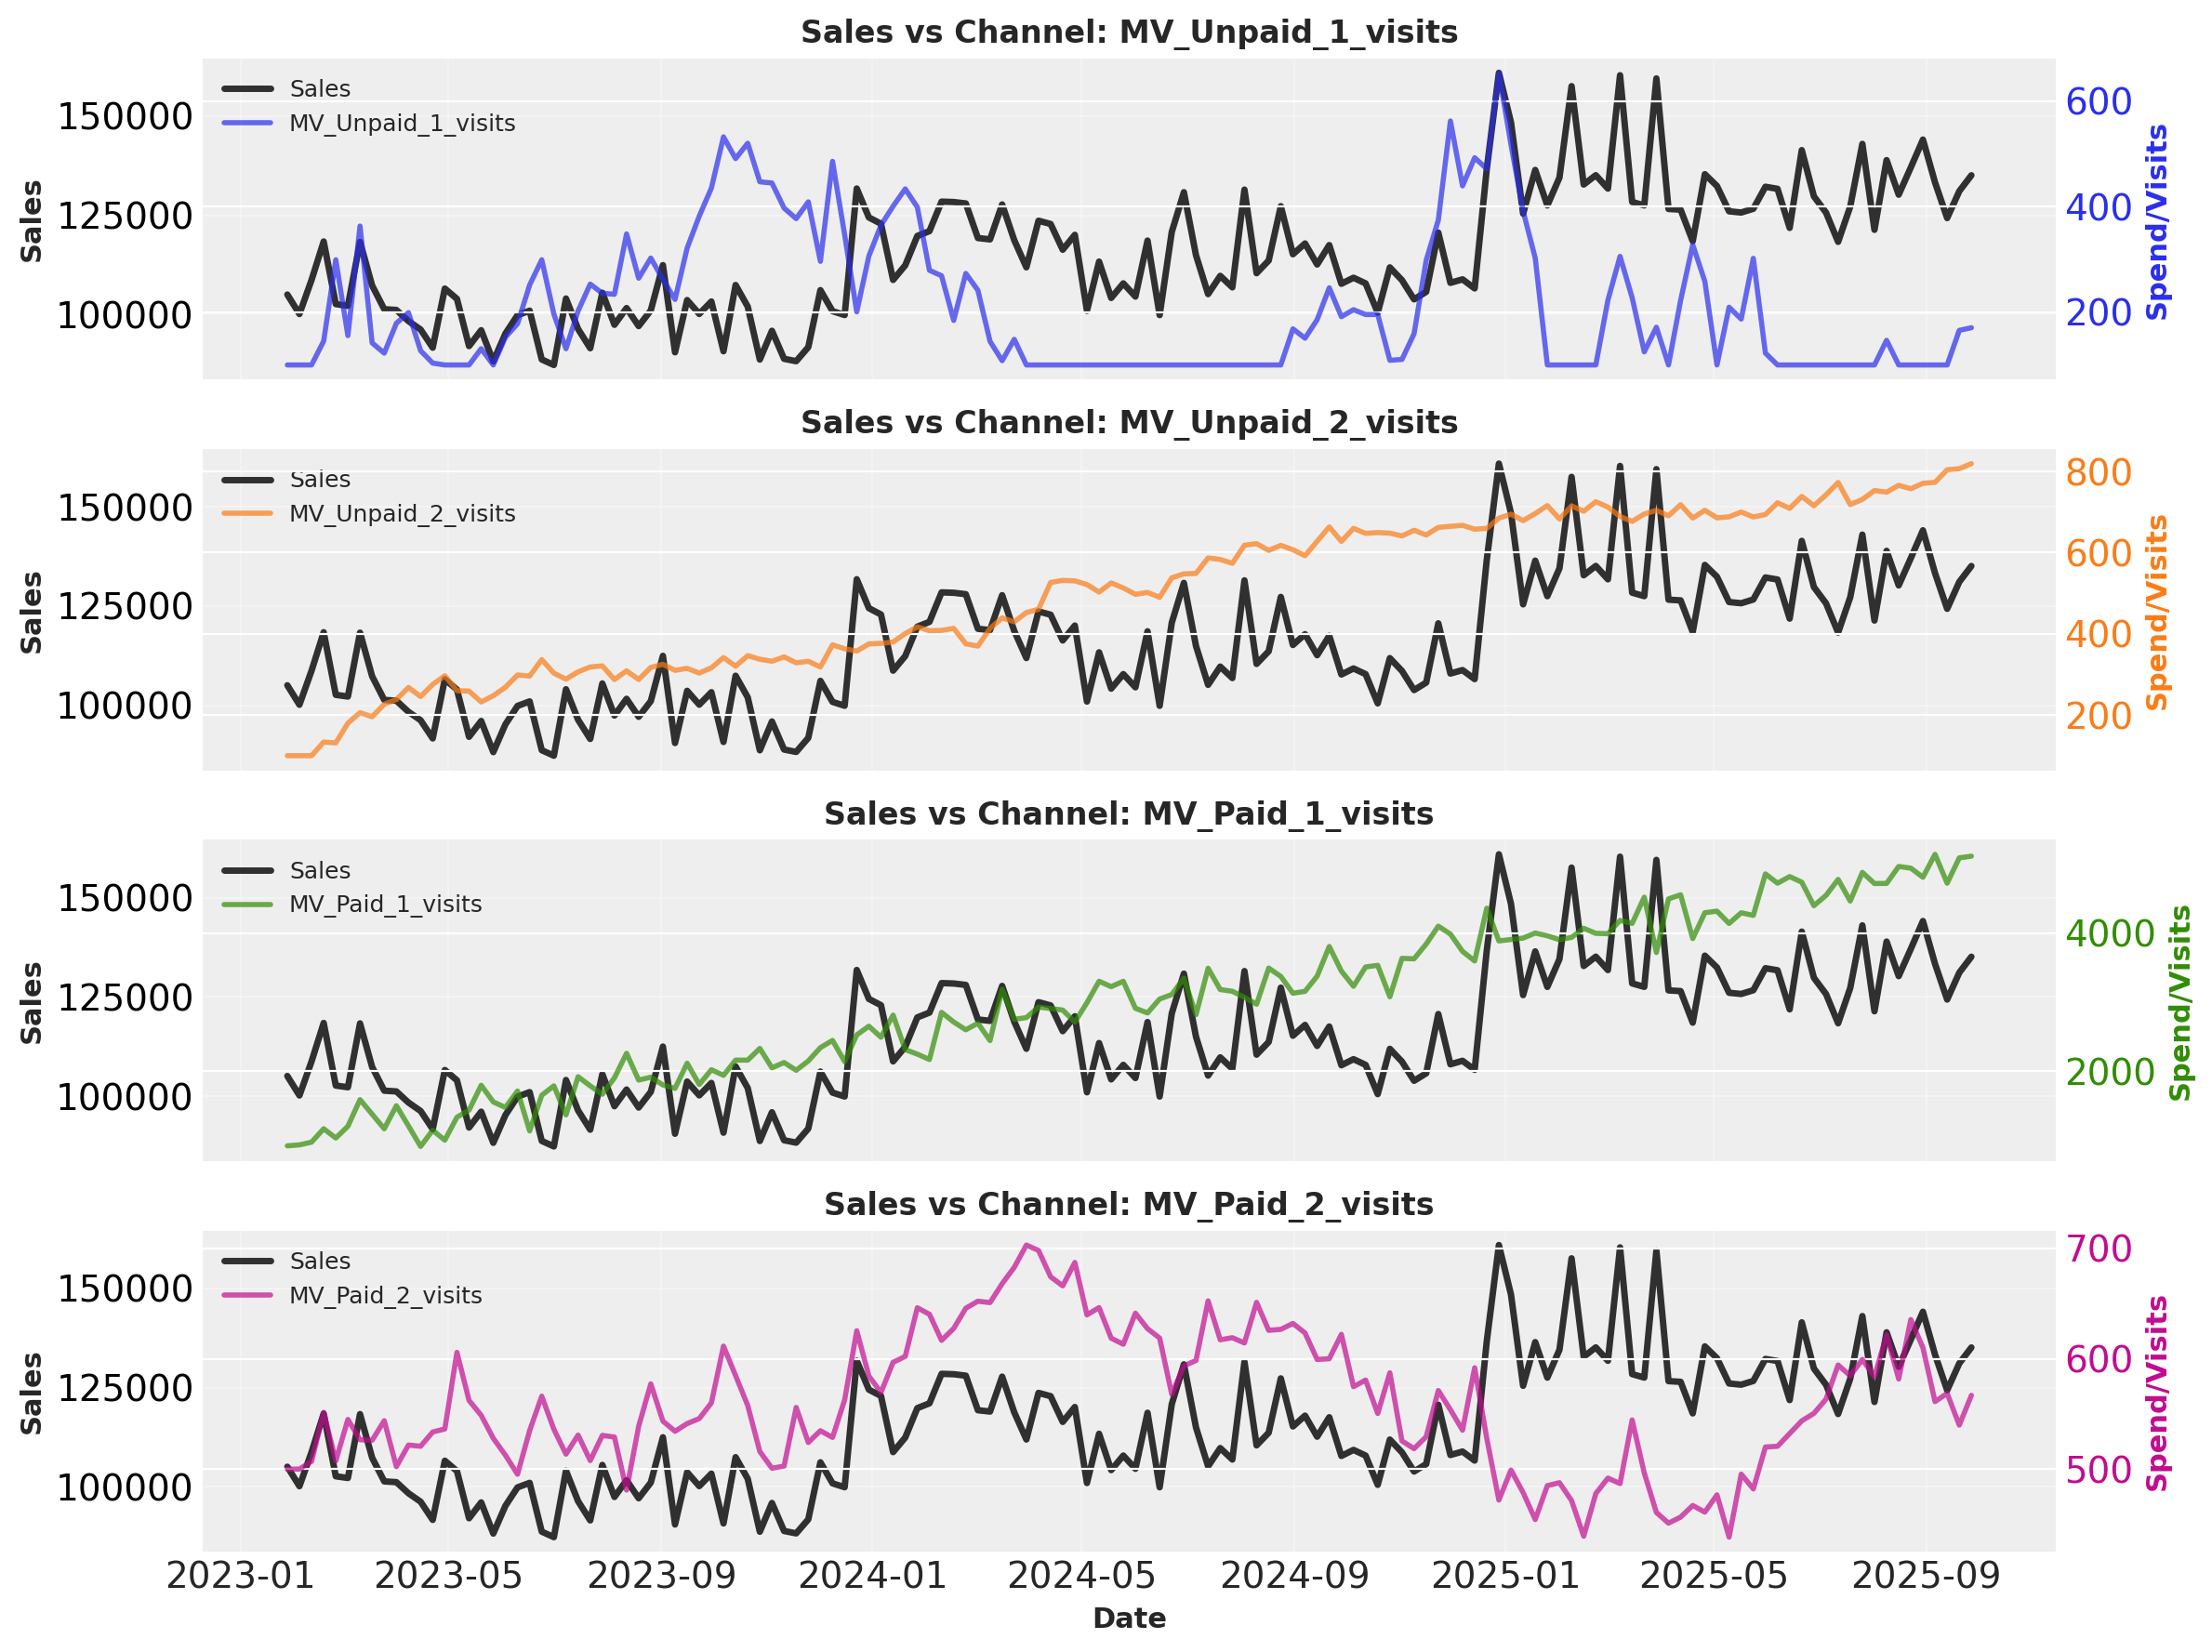

In [7]:
# Usage example:
fig, axes = plot_sales_and_channels(data, config)
plt.show()

# Data cleaning (if needed)

In [8]:
# Add a simple linear trend feature
data["t"] = range(len(data))

# Split into features (X) and target (y) using standardized 'y'
target_col = "y"
X = data.drop(target_col, axis=1)
y = data[target_col]


X.drop(["Intercept", "Trend", "Fourier_cos_1", "Fourier_sin_1", "Fourier_sin_2", "Fourier_cos_2"], axis=1, inplace=True)

X

,week_start_date,Holiday_Christmas,Control_1,Control_2,MV_Unpaid_1_visits,MV_Unpaid_2_visits,MV_Paid_1_Spend,MV_Paid_1_visits,MV_Paid_2_Spend,MV_Paid_2_visits,t
0,2023-01-28,0,0.496714,116.381149,100.000000,100.000000,917.624607,18165.940444,500.000000,3843.416917,0
1,2023-02-04,0,0.138264,112.424026,100.000000,100.000000,931.255734,18494.753023,500.000000,4008.569354,1
2,2023-02-11,0,0.647689,110.592654,100.000000,100.000000,971.042319,17738.157316,507.026442,2928.068871,2
3,2023-02-18,0,1.523030,106.106006,145.219227,133.585944,1165.221364,18982.038773,551.433524,4546.707517,3
4,2023-02-25,0,0.234153,104.627937,299.298986,131.501936,1030.911018,18319.456422,507.458134,2505.155811,4
...,...,...,...,...,...,...,...,...,...,...,...
135,2025-08-30,0,1.549934,196.286780,100.000000,770.823545,4812.698853,20783.963568,610.021888,5028.114854,135
136,2025-09-06,0,0.783253,197.787187,100.000000,773.186912,5145.535025,21264.790875,561.203334,6542.927561,136
137,2025-09-13,0,0.322062,198.857567,100.000000,804.255962,4726.233378,20884.515055,568.689844,4938.199320,137
138,2025-09-20,0,0.813517,198.999152,165.577047,806.680422,5094.410143,21299.063318,539.892008,4960.643244,138


# Prior selection

#### Show which type of priors we have chosen (customized prior or spend per channel heuristics)

In [9]:
# Calculate spend share for each channel
total_spend_per_channel = data[channel_cols].sum(axis=0)
spend_share = total_spend_per_channel / total_spend_per_channel.sum()

print("=" * 70)
print("SPEND SHARE PER CHANNEL")
print("=" * 70)
print(spend_share)
print("=" * 70)

SPEND SHARE PER CHANNEL
MV_Unpaid_1_visits    0.008237
MV_Unpaid_2_visits    0.019467
MV_Paid_1_visits      0.775956
MV_Paid_2_visits      0.196340
dtype: float64


##### Setting priors

In [10]:
# ============================================================================
# BUILD MODEL CONFIGURATION FROM INLINE CONFIG
# ============================================================================

# Get global prior configuration
prior_config = config['priors']

# Build channel-specific priors from inline definitions
channels = config['data']['columns']['channels']
adstock_alpha_priors = [
    Prior(
        ch['adstock']['prior']['distribution'],
        **{k: v for k, v in ch['adstock']['prior'].items() if k != 'distribution'}
    )
    for ch in channels
]

saturation_beta_priors = [
    Prior(
        ch['saturation']['prior']['distribution'],
        **{k: v for k, v in ch['saturation']['prior'].items() if k != 'distribution'}
    )
    for ch in channels
]

# Build control-specific priors from inline definitions
controls = config['data']['columns']['controls']
gamma_control_priors = [
    Prior(
        ctrl['prior']['distribution'],
        **{k: v for k, v in ctrl['prior'].items() if k != 'distribution'}
    )
    for ctrl in controls
]

# Build the model_config dictionary
my_model_config = {
    "intercept": Prior(
        prior_config['intercept']['distribution'],
        mu=prior_config['intercept']['mu'],
        sigma=prior_config['intercept']['sigma']
    ),
    "gamma_control": PerChannelDistributionFactory(gamma_control_priors),
    "gamma_fourier": Prior(
        prior_config['gamma_fourier']['distribution'],
        mu=prior_config['gamma_fourier']['mu'],
        b=prior_config['gamma_fourier']['b']
    ),
    "likelihood": Prior(
        prior_config['likelihood']['distribution'],
        sigma=Prior(
            prior_config['likelihood']['sigma']['distribution'],
            sigma=prior_config['likelihood']['sigma']['sigma']
        )
    ),
    "adstock_alpha": PerChannelDistributionFactory(adstock_alpha_priors),
    "saturation_beta": PerChannelDistributionFactory(saturation_beta_priors),
}

print("=" * 70)
print("MODEL CONFIG BUILT FROM INLINE PARAMETERS")
print("=" * 70)
print(f"Number of channels: {len(channels)}")
print(f"Number of controls: {len(controls)}")
print(f"Adstock priors: {len(adstock_alpha_priors)} defined")
print(f"Saturation priors: {len(saturation_beta_priors)} defined")
print(f"Control priors: {len(gamma_control_priors)} defined")
print("=" * 70)

MODEL CONFIG BUILT FROM INLINE PARAMETERS
Number of channels: 4
Number of controls: 3
Adstock priors: 4 defined
Saturation priors: 4 defined
Control priors: 3 defined


#### Getting model configurations

In [11]:
# Sampler configuration
my_sampler_config = {"progressbar": progress_bar}

##### Instantiating MMM model object

In [12]:

# Initialize the MMM model with configuration
mmm = MMM(
    model_config=my_model_config,
    sampler_config=my_sampler_config,
    date_column=date_col,
    adstock=create_adstock_from_config(adstock_config),
    saturation=create_saturation_from_config(saturation_config),
    apply_scaling=apply_scaling,
    channel_columns=channel_cols,
    control_columns=control_cols,
    yearly_seasonality=yearly_seasonality,
    fit_intercept=fit_intercept,
    log_transform_vars=log_transform_vars
)

# Prior Predictive Check

> **Tip**: The prior predictive check is a good way to check that our priors are reasonable. Hence, it is strongly recommended to perform this check before fitting the model. If you are new to Bayesian modeling, take a look into our Prior Predictive Modeling guide notebook.

Before fitting, let's check that our priors are reasonable:

In [13]:
# Sanity check: verify logger handlers before prior predictive
import logging

print("=== Logger state before prior predictive ===")
root = logging.getLogger()
print(f"Root handlers: {len(root.handlers)} -> {root.handlers}")

# Show relevant package loggers
for name in sorted([n for n in logging.root.manager.loggerDict.keys() if str(n).startswith("pymc_marketing")]):
    lg = logging.getLogger(name)
    # Some entries in loggerDict are PlaceHolder; only print real Loggers
    if isinstance(lg, logging.Logger):
        print(f"{name}: level={logging.getLevelName(lg.level)}, handlers={len(lg.handlers)}, propagate={lg.propagate}")


=== Logger state before prior predictive ===
Root handlers: 2 -> [<StreamHandler stderr (NOTSET)>, <NullHandler (NOTSET)>]
pymc_marketing: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm.mmm: level=NOTSET, handlers=0, propagate=True
pymc_marketing.mmm.mmm.MMM: level=Level 51, handlers=1, propagate=False


In [14]:
mmm.sample_prior_predictive(X, y, samples=prior_samples, random_seed=rng)


Sampling: [adstock_alpha_ch0, adstock_alpha_ch1, adstock_alpha_ch2, adstock_alpha_ch3, gamma_control_ch0, gamma_control_ch1, gamma_control_ch2, gamma_fourier, intercept, saturation_beta_ch0, saturation_beta_ch1, saturation_beta_ch2, saturation_beta_ch3, y, y_sigma]
2026-01-04 22:49:19,791 - pymc.sampling.forward - INFO - Sampling: [adstock_alpha_ch0, adstock_alpha_ch1, adstock_alpha_ch2, adstock_alpha_ch3, gamma_control_ch0, gamma_control_ch1, gamma_control_ch2, gamma_fourier, intercept, saturation_beta_ch0, saturation_beta_ch1, saturation_beta_ch2, saturation_beta_ch3, y, y_sigma]


<xarray.Dataset> Size: 344kB
Dimensions:  (date: 140, sample: 300)
Coordinates:
  * date     (date) datetime64[ns] 1kB 2023-01-28 2023-02-04 ... 2025-09-27
  * sample   (sample) object 2kB MultiIndex
  * chain    (sample) int64 2kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * draw     (sample) int64 2kB 0 1 2 3 4 5 6 7 ... 293 294 295 296 297 298 299
Data variables:
    y        (date, sample) float64 336kB 37.02 28.79 49.17 ... 23.82 20.74
Attributes:
    created_at:                 2026-01-05T03:49:28.376326+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.25.1
    pymc_marketing_version:     0.16.0


PRIOR PREDICTIVE TRANSFORMATION DEBUG
Predictions shape: (1, 300, 140)
Predictions sample (first 5): [37.02061436 35.19569625 37.04186721 35.84792194 33.92414205]
Predictions mean: 26.54

✓ Reverting log transformation: exp(x)
  Model has log_transform_vars: ['target', 'channels']
  After log reversion - mean: 403736067201.35

○ Scale reversion SKIPPED (original_scale=False)

PLOT STATISTICS:
  Observed Y - mean: 115382.95, range: [87318.95, 160913.87]
  Predicted Y - mean: 403736067201.35, range: [13694925990.31, 1750214708487.64]
  94% HDI - lower mean: 1780.81, upper mean: 860563724961493811200.00
  50% HDI - lower mean: 3752728629.05, upper mean: 3188034118703636.50

  Scale ratio (observed/predicted): 0.0000


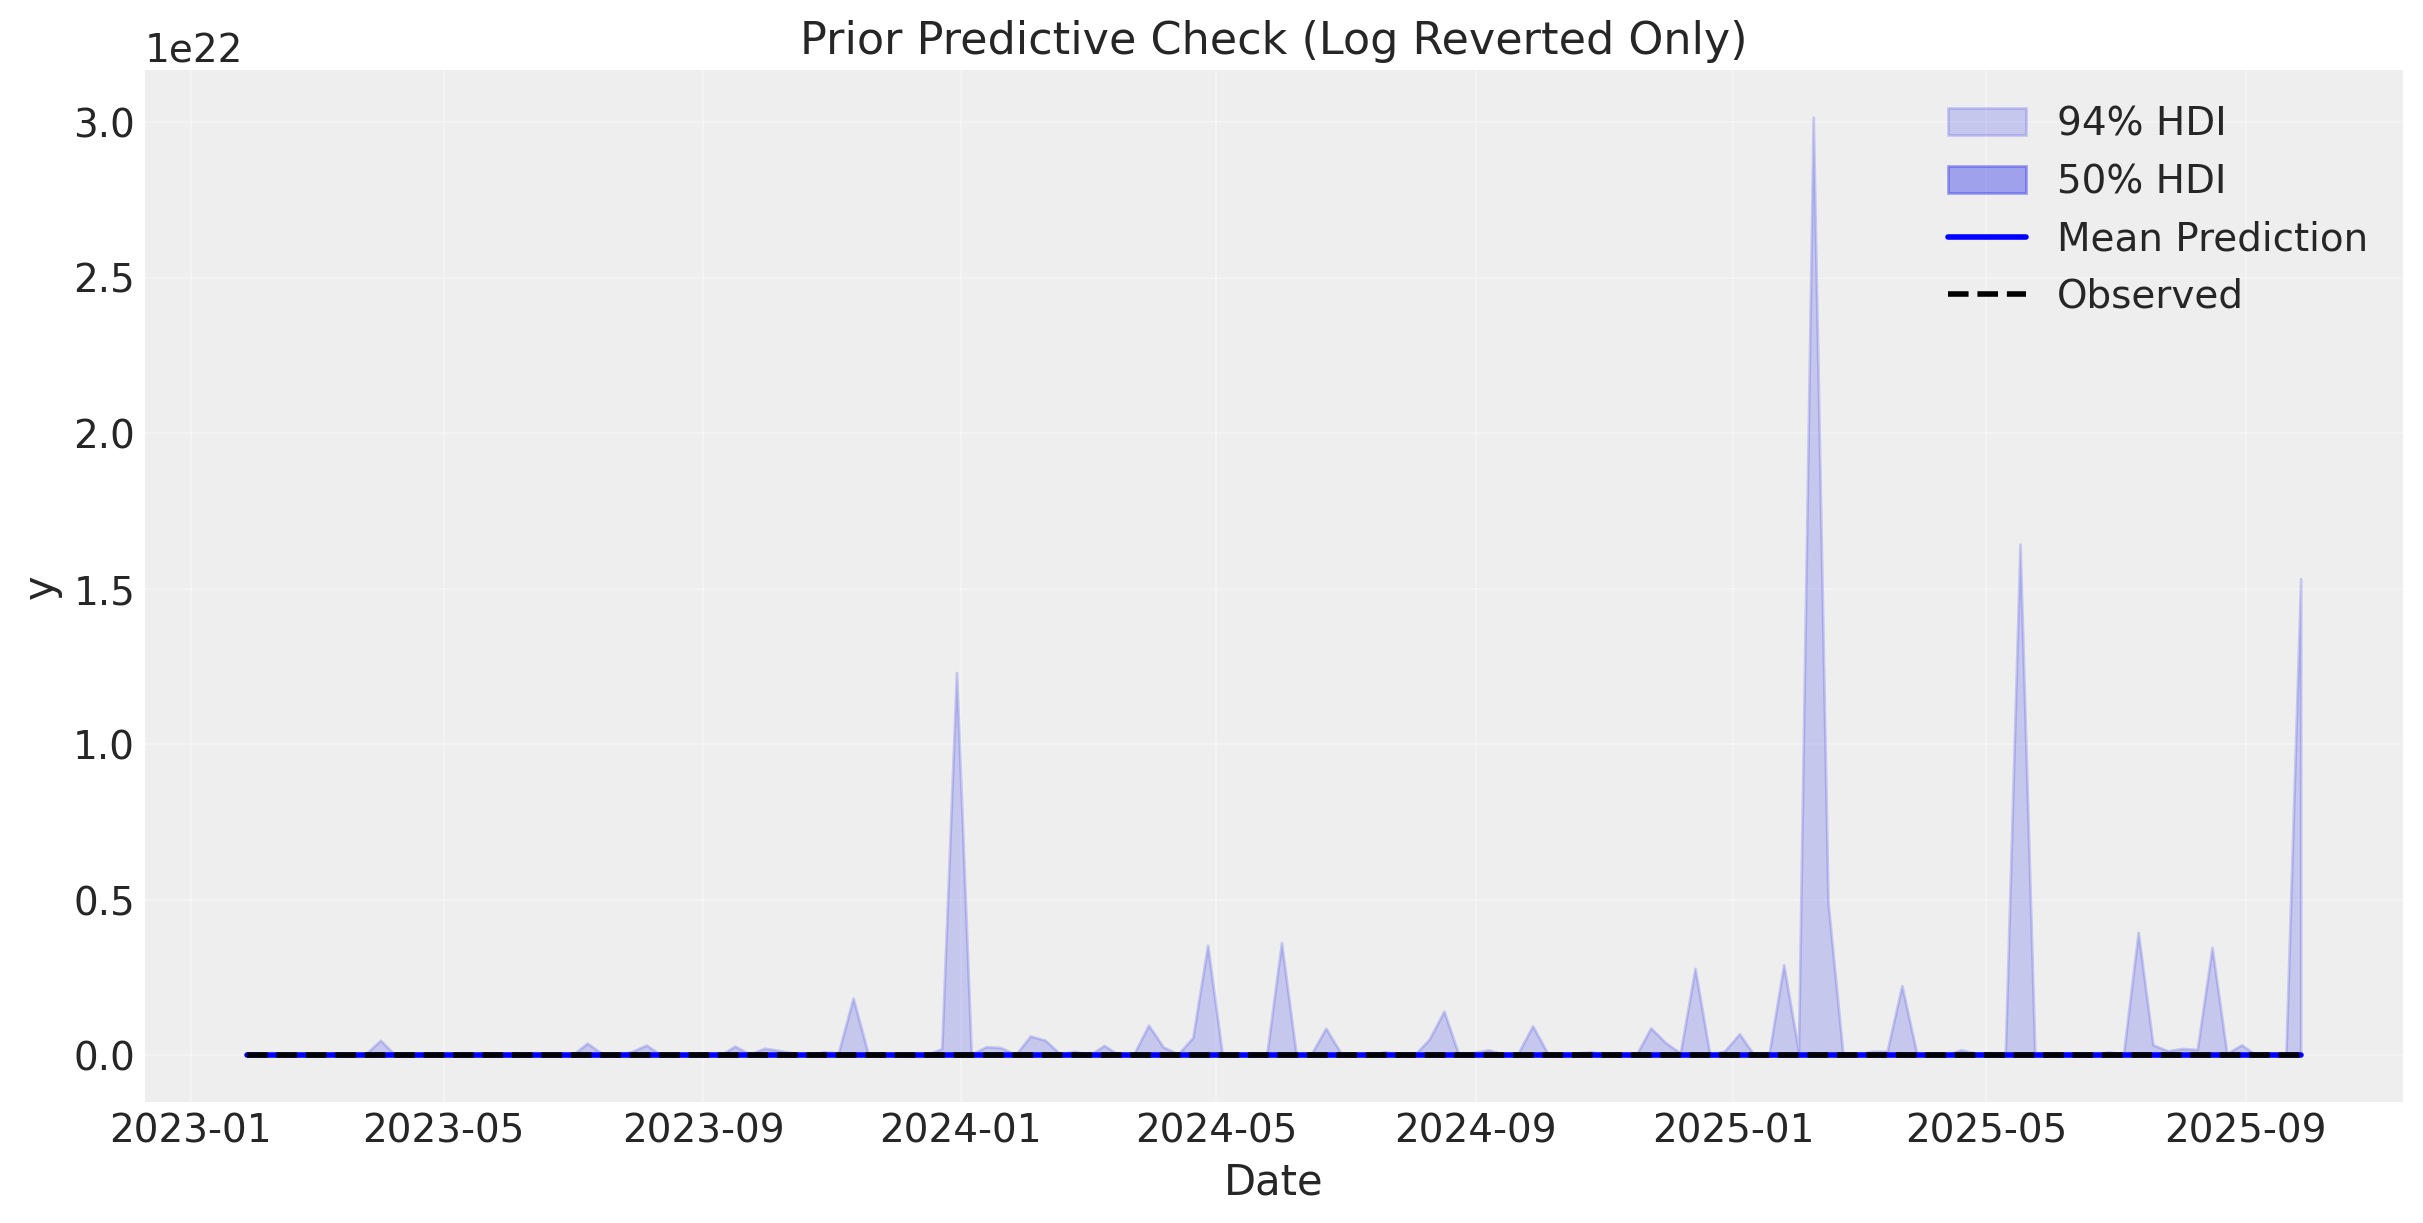

In [15]:
# USAGE:
fig, ax = plot_prior_predictive_with_log_reversion(
    mmm,
    original_scale=False,
    revert_log=True
)
plt.show()

In [16]:
# Verify heterogeneous distributions
print("=" * 70)
print("Distribution types created:")
print("=" * 70)

for rv in mmm.model.free_RVs:
    if 'adstock_alpha' in rv.name:
        dist_type = type(rv.owner.op).__name__
        print(f"{rv.name:30s} -> {dist_type}")

Distribution types created:
adstock_alpha_ch0              -> BetaRV
adstock_alpha_ch1              -> BetaRV
adstock_alpha_ch2              -> BetaRV
adstock_alpha_ch3              -> BetaRV


# Model Fitting


In [17]:
# Fit the model using MCMC configuration from config file
mcmc_config = config['sampling']['mcmc']

_ = mmm.fit(
    X=X,
    y=y,
    chains=mcmc_config['chains'],
    target_accept=mcmc_config['target_accept'],
    nuts_sampler=mcmc_config['nuts_sampler'],
    random_seed=rng,
)

Running chain 1: 100%|██████████| 2000/2000 [01:28<00:00, 22.66it/s]
We recommend running at least 4 chains for robust computation of convergence diagnostics
2026-01-04 22:51:01,479 - pymc.stats.convergence - INFO - We recommend running at least 4 chains for robust computation of convergence diagnostics


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

# Model Diagnostics

After fitting, we should check the model quality. Let's start with divergences:

In [18]:
# Check for divergences
n_divergences = mmm.idata["sample_stats"]["diverging"].sum().item()
print(f"Number of divergences: {n_divergences}")

if n_divergences == 0:
    print("✓ No divergences - sampling was successful!")
else:
    print("⚠ Warning: Model had divergences. Consider increasing target_accept.")

Number of divergences: 0
✓ No divergences - sampling was successful!


# Parameter Summary

Let's examine the estimated parameters:

In [19]:
mmm.fit_result

<xarray.Dataset> Size: 52MB
Dimensions:                                         (chain: 2, draw: 1000,
                                                     fourier_mode: 4,
                                                     date: 140, channel: 4,
                                                     control: 3)
Coordinates:
  * chain                                           (chain) int64 16B 0 1
  * draw                                            (draw) int64 8kB 0 1 ... 999
  * fourier_mode                                    (fourier_mode) <U5 80B 's...
  * date                                            (date) datetime64[ns] 1kB ...
  * channel                                         (channel) <U18 288B 'MV_U...
  * control                                         (control) <U17 204B 'Cont...
Data variables: (12/25)
    adstock_alpha_ch0                               (chain, draw) float64 16kB ...
    adstock_alpha_ch1                               (chain, draw) float64 16kB ...
    adstock_alpha_ch2                               (chain, draw) float64 16kB ...
    adstock_alpha_ch3                               (chain, draw) float64 16kB ...
    gamma_control_ch0                               (chain, draw) float64 16kB ...
    gamma_control_ch1                               (chain, draw) float64 16kB ...
    ...                                              ...
    mu                                              (chain, draw, date) float64 2MB ...
    total_contribution                              (chain, draw) float64 16kB ...
    total_contribution_original_scale               (chain, draw, date) float64 2MB ...
    y_original_scale                                (chain, draw, date) float64 2MB ...
    yearly_seasonality_contribution                 (chain, draw, date) float64 2MB ...
    yearly_seasonality_contribution_original_scale  (chain, draw, date) float64 2MB ...
Attributes:
    created_at:                 2026-01-05T03:51:01.273379+00:00
    arviz_version:              0.22.0
    inference_library:          numpyro
    inference_library_version:  0.19.0
    sampling_time:              88.618772
    tuning_steps:               1000
    pymc_marketing_version:     0.16.0

PARAMETER MAPPING:
  adstock_alpha_ch0              → MV_Unpaid_1_visits
  adstock_alpha_ch1              → MV_Unpaid_2_visits
  adstock_alpha_ch2              → MV_Paid_1_visits
  adstock_alpha_ch3              → MV_Paid_2_visits
  saturation_beta_ch0            → MV_Unpaid_1_visits
  saturation_beta_ch1            → MV_Unpaid_2_visits
  saturation_beta_ch2            → MV_Paid_1_visits
  saturation_beta_ch3            → MV_Paid_2_visits
  gamma_control_ch0              → Control_1
  gamma_control_ch1              → Control_2
  gamma_control_ch2              → Holiday_Christmas
  intercept                      → intercept


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\utils.py:200: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


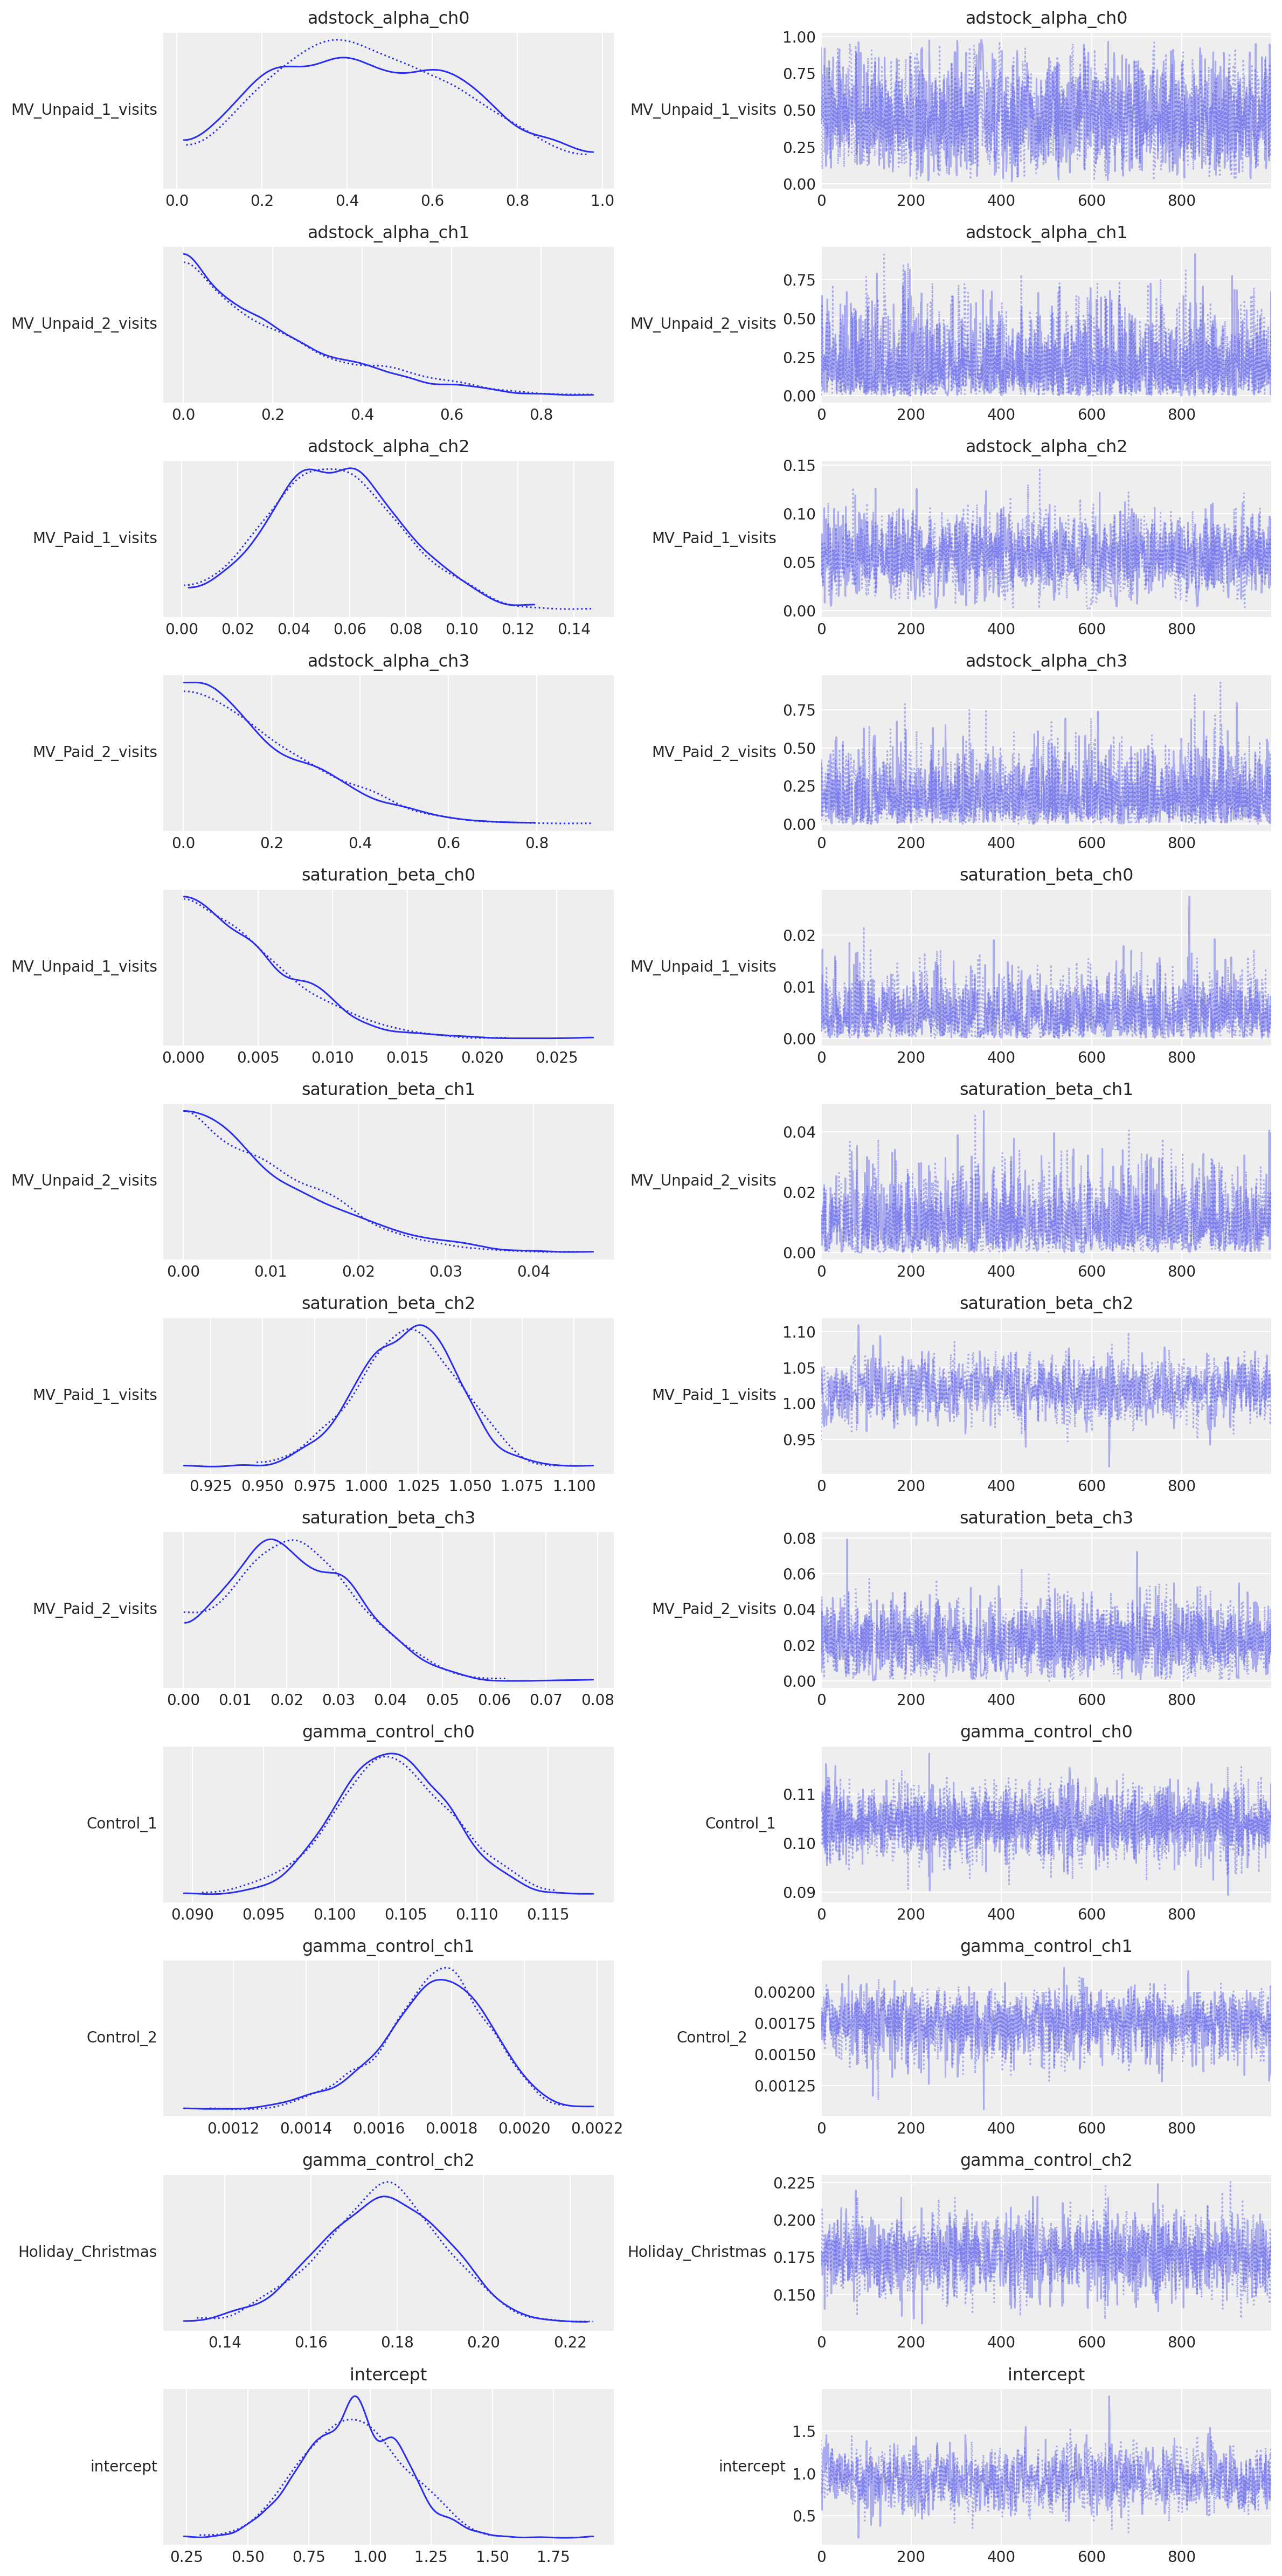

In [20]:
# 2. Comprehensive trace plot
fig = plot_trace_with_channel_names(
    mmm, 
    config,
    include_params=['adstock_alpha', 'saturation_beta', 'gamma_control', 'intercept']
)

Good trace plots should show:

- **Left side**: Smooth, bell-shaped distributions
- **Right side**: "Fuzzy caterpillar" patterns (good mixing) with no trends

In [21]:
# Summary table
summary_df = summary_with_channel_names(mmm, config, include_params=['adstock_alpha', 'saturation_beta', 'gamma_control', 'intercept'])


In [22]:
summary_df

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
adstock_alpha[MV_Unpaid_1_visits],0.458,0.222,0.077,0.870,0.006,0.004,1544.0,934.0,1.0
adstock_alpha[MV_Unpaid_2_visits],0.211,0.179,0.000,0.550,0.003,0.004,2287.0,1128.0,1.0
adstock_alpha[MV_Paid_1_visits],0.055,0.023,0.012,0.100,0.001,0.001,1166.0,514.0,1.0
adstock_alpha[MV_Paid_2_visits],0.191,0.151,0.000,0.462,0.003,0.003,1924.0,928.0,1.0
saturation_beta[MV_Unpaid_1_visits],0.005,0.004,0.000,0.011,0.000,0.000,1158.0,899.0,1.0
saturation_beta[MV_Unpaid_2_visits],0.010,0.008,0.000,0.025,0.000,0.000,1080.0,691.0,1.0
saturation_beta[MV_Paid_1_visits],1.019,0.024,0.974,1.063,0.001,0.001,939.0,1110.0,1.0
saturation_beta[MV_Paid_2_visits],0.022,0.012,0.000,0.042,0.000,0.000,1449.0,666.0,1.0
gamma_control[Control_1],0.104,0.004,0.096,0.112,0.000,0.000,3606.0,1565.0,1.0
gamma_control[Control_2],0.002,0.000,0.001,0.002,0.000,0.000,1934.0,1788.0,1.0


# Posterior Predictive Check

How well does our model fit the observed data?

In [23]:
# Sample from posterior predictive distribution
mmm.sample_posterior_predictive(X, extend_idata=True, combined=True)


Sampling: [y]
2026-01-04 22:51:55,805 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<xarray.Dataset> Size: 2MB
Dimensions:  (date: 140, sample: 2000)
Coordinates:
  * date     (date) datetime64[ns] 1kB 2023-01-28 2023-02-04 ... 2025-09-27
  * sample   (sample) object 16kB MultiIndex
  * chain    (sample) int64 16kB 0 0 0 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1 1 1 1 1
  * draw     (sample) int64 16kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
Data variables:
    y        (date, sample) float64 2MB 11.49 11.48 11.52 ... 11.86 11.8 11.78
Attributes:
    created_at:                 2026-01-05T03:51:55.950669+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.25.1


POSTERIOR PREDICTIVE TRANSFORMATION DEBUG
Predictions shape: (2, 1000, 140)
Predictions sample (first 5): [11.48781929 11.49353143 11.52353655 11.7206112  11.53805233]
Predictions mean: 11.65

✓ Reverting log transformation: exp(x)
  Model has log_transform_vars: ['target', 'channels']
  After log reversion - mean: 115403.34

✓ Reverting scaling: multiply by target_scale=1.0
  After scale reversion - mean: 115403.34

PLOT STATISTICS:
  Observed Y - mean: 115382.95, range: [87318.95, 160913.87]
  Predicted Y - mean: 115403.34, range: [87038.62, 167050.19]
  94% HDI - lower mean: 109283.47, upper mean: 121859.50
  50% HDI - lower mean: 113137.64, upper mean: 117584.29

  Scale ratio (observed/predicted): 0.9998


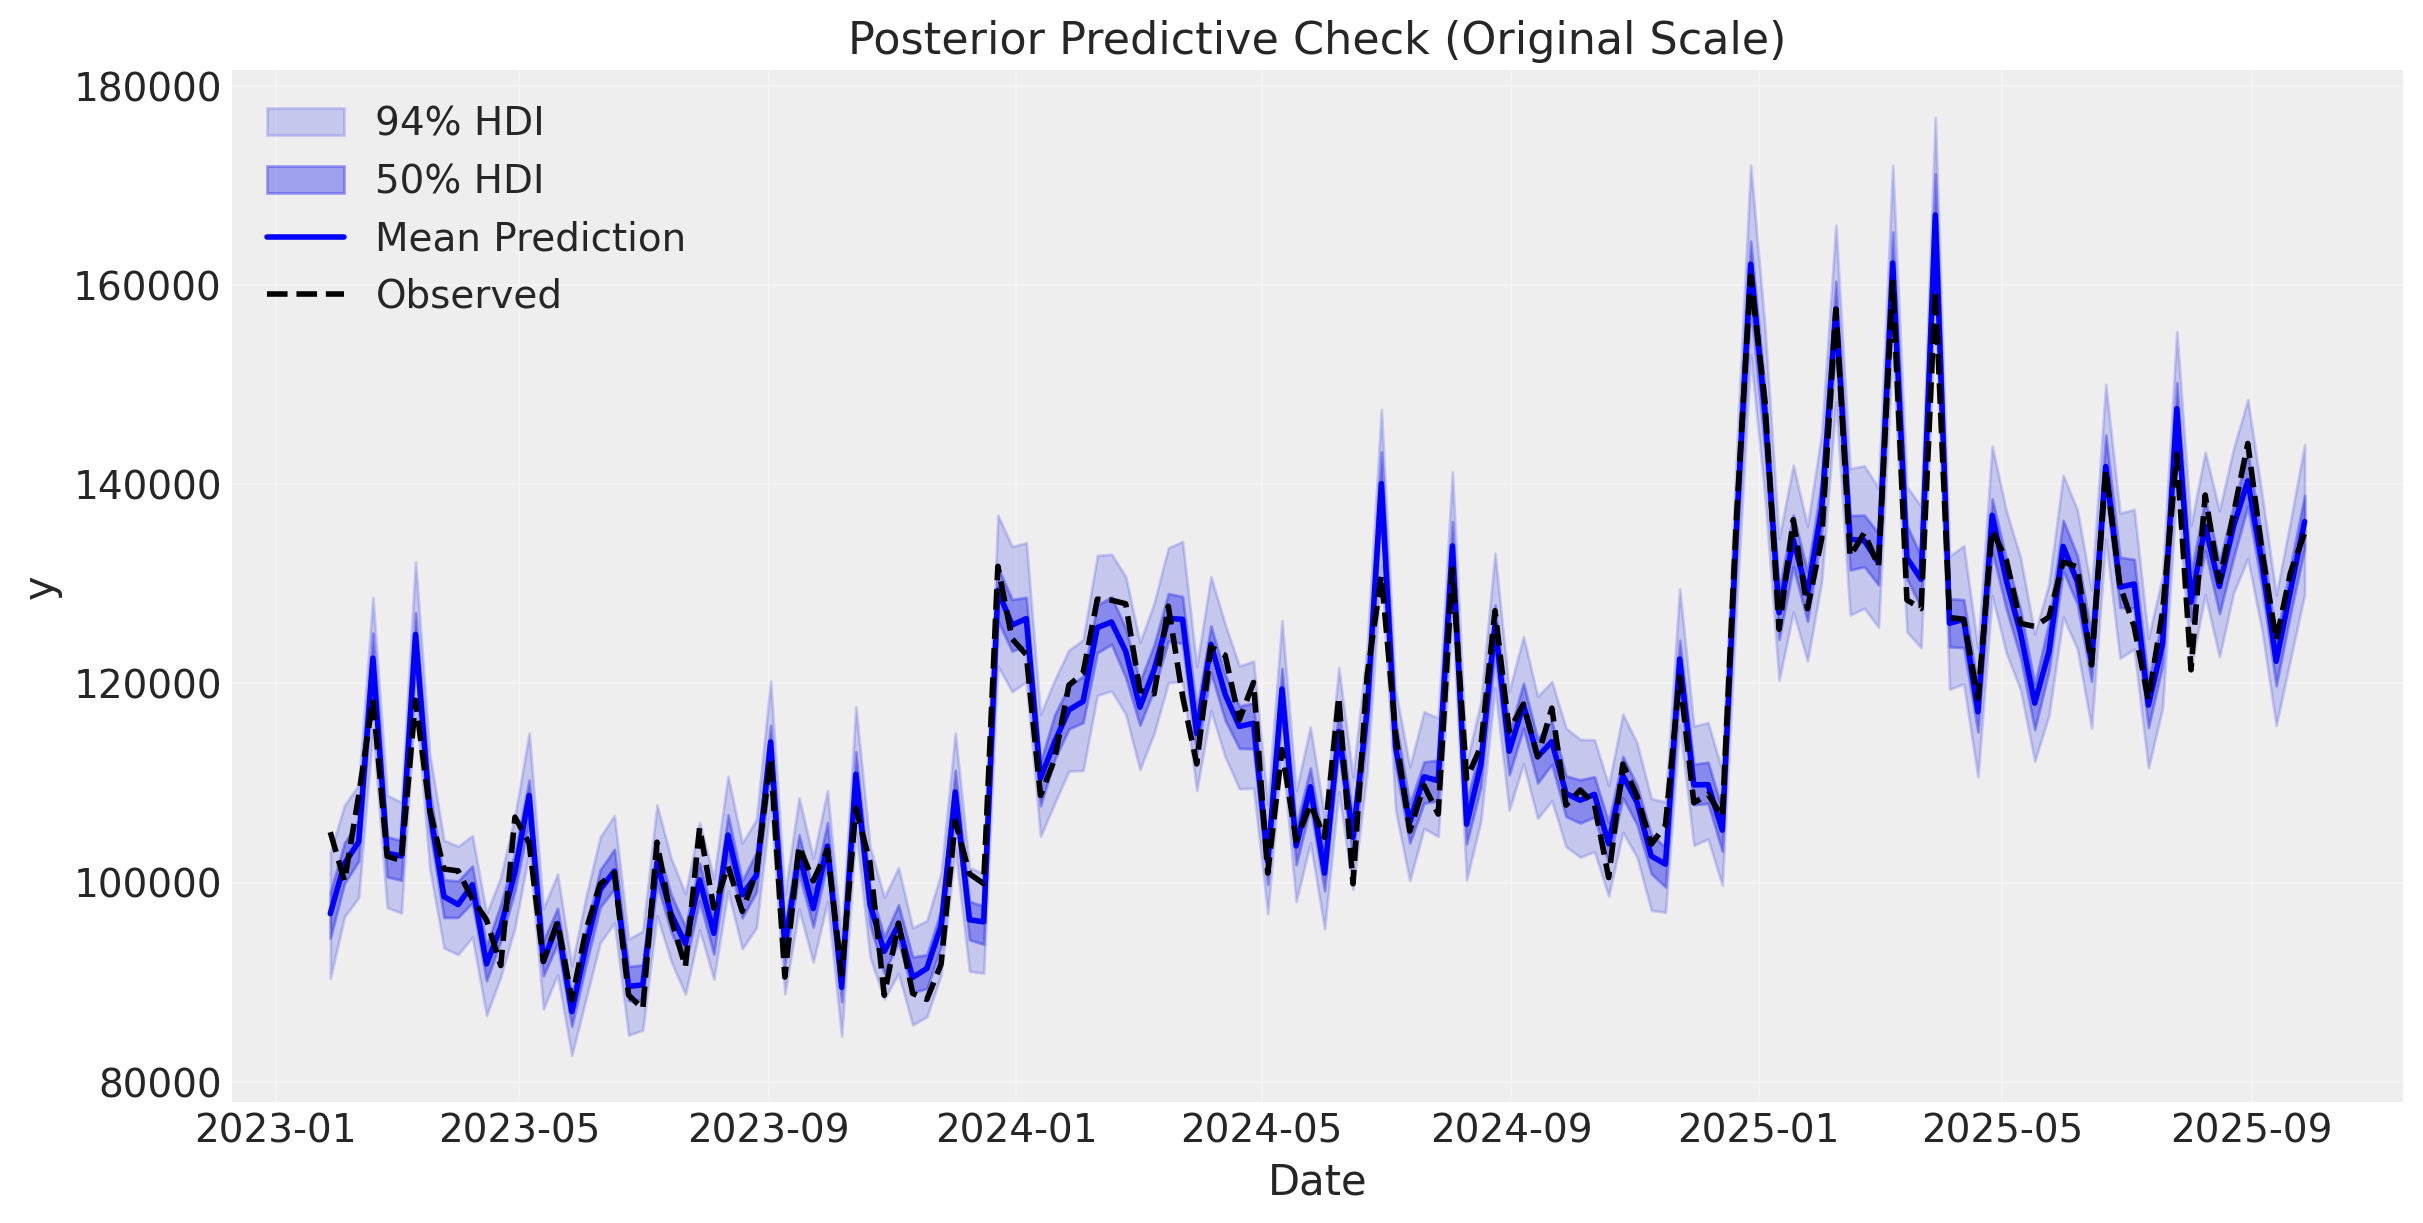

In [24]:
# For POSTERIOR predictive (after mmm.sample_posterior_predictive)
fig, ax = plot_posterior_predictive_with_log_reversion(
    mmm,
    original_scale=True,
    revert_log=True
)
plt.show()

# Get model coefficients (optional)

In [25]:
coefs = mmm.extract_coefficients(verbose = True)
coefs["fit_metrics"]

[DEBUG] Applying scaling by target_scale=1.0
EXTRACTING ALL MODEL COEFFICIENTS FOR MANUAL CALCULATION

1. INTERCEPT
--------------------------------------------------------------------------------
parameter     mean      std    ci_5%   ci_95%
intercept 0.932383 0.204196 0.600816 1.278264

2. SCALING AND TRANSFORMATION PARAMETERS
--------------------------------------------------------------------------------
                       parameter  value                                 description
             target_scale_factor    1.0        Factor used to scale target variable
              log_epsilon_target    1.0           Epsilon for log(target + epsilon)
            log_epsilon_channels    1.0         Epsilon for log(channels + epsilon)
channel_scale_MV_Unpaid_1_visits    1.0 Scale factor for channel MV_Unpaid_1_visits
channel_scale_MV_Unpaid_2_visits    1.0 Scale factor for channel MV_Unpaid_2_visits
  channel_scale_MV_Paid_1_visits    1.0   Scale factor for channel MV_Paid_1_visits


,metric,value,description
0,MAPE,1.019464,Mean Absolute Percentage Error
1,MAE,115371.304876,Mean Absolute Error
2,RMSE,116510.774027,Root Mean Squared Error
3,R²,-50.375377,Coefficient of determination


# Get raw component contributions using one off method

### contribution MV_Unpaid_1_visits

In [26]:
# # Example 1: Plot the comparison
# fig = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Unpaid_1_visits'],
#     original_scale=False
# )

In [27]:
# # Extract predictions as dictionary
# predictions_dict = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Unpaid_1_visits'],
#     original_scale=True,
#     return_predictions=True,
#     random_seed=seed
# )

# print("\n=== EXTRACTED PREDICTIONS ===")
# print(f"Keys in dictionary: {list(predictions_dict.keys())}")
# print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
# print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
# print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
# print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

### contribution MV_Unpaid_2_visits

In [28]:
# # Example 1: Plot the comparison
# fig = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Unpaid_2_visits'],
#     original_scale=True)

In [29]:
# # Extract predictions as dictionary
# predictions_dict = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Unpaid_2_visits'],
#     original_scale=True,
#     return_predictions=True,
#     random_seed=seed
# )

# print("\n=== EXTRACTED PREDICTIONS ===")
# print(f"Keys in dictionary: {list(predictions_dict.keys())}")
# print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
# print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
# print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
# print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

### contribution MV_Paid_1_Spend

In [30]:
# # Example 1: Plot the comparison
# fig = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Paid_1_Spend'],
#     original_scale=True)

In [31]:
# # Extract predictions as dictionary
# predictions_dict = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Paid_1_Spend'],
#     original_scale=True,
#     return_predictions=True,
#     random_seed=seed
# )

# print("\n=== EXTRACTED PREDICTIONS ===")
# print(f"Keys in dictionary: {list(predictions_dict.keys())}")
# print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
# print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
# print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
# print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

### contribution MV_Paid_2_Spend

In [32]:
# # Example 1: Plot the comparison
# fig = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Paid_2_Spend'],
#     original_scale=True,
#     random_seed=seed)

In [33]:
# # Extract predictions as dictionary
# predictions_dict = compare_predictions(
#     mmm=mmm,
#     data=data,
#     shutdown_channels=['MV_Paid_2_Spend'],
#     original_scale=True,
#     return_predictions=True
# )

# print("\n=== EXTRACTED PREDICTIONS ===")
# print(f"Keys in dictionary: {list(predictions_dict.keys())}")
# print(f"\nOriginal predictions shape: {predictions_dict['original_mean'].shape}")
# print(f"Modified predictions shape: {predictions_dict['modified_mean'].shape}")
# print(f"\nOriginal mean (first 5): {predictions_dict['original_mean'][:5]}")
# print(f"Modified mean (first 5): {predictions_dict['modified_mean'][:5]}")

# Get adjusted Component contributions 


Sampling: [y]
2026-01-04 22:51:56,961 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling: [y]
2026-01-04 22:51:57,210 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling: [y]
2026-01-04 22:52:14,435 - pymc.sampling.forward - INFO - Sampling: [y]


...

Sampling: [y]
2026-01-04 22:53:04,149 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling: [y]
2026-01-04 22:53:04,354 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:295: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:347: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


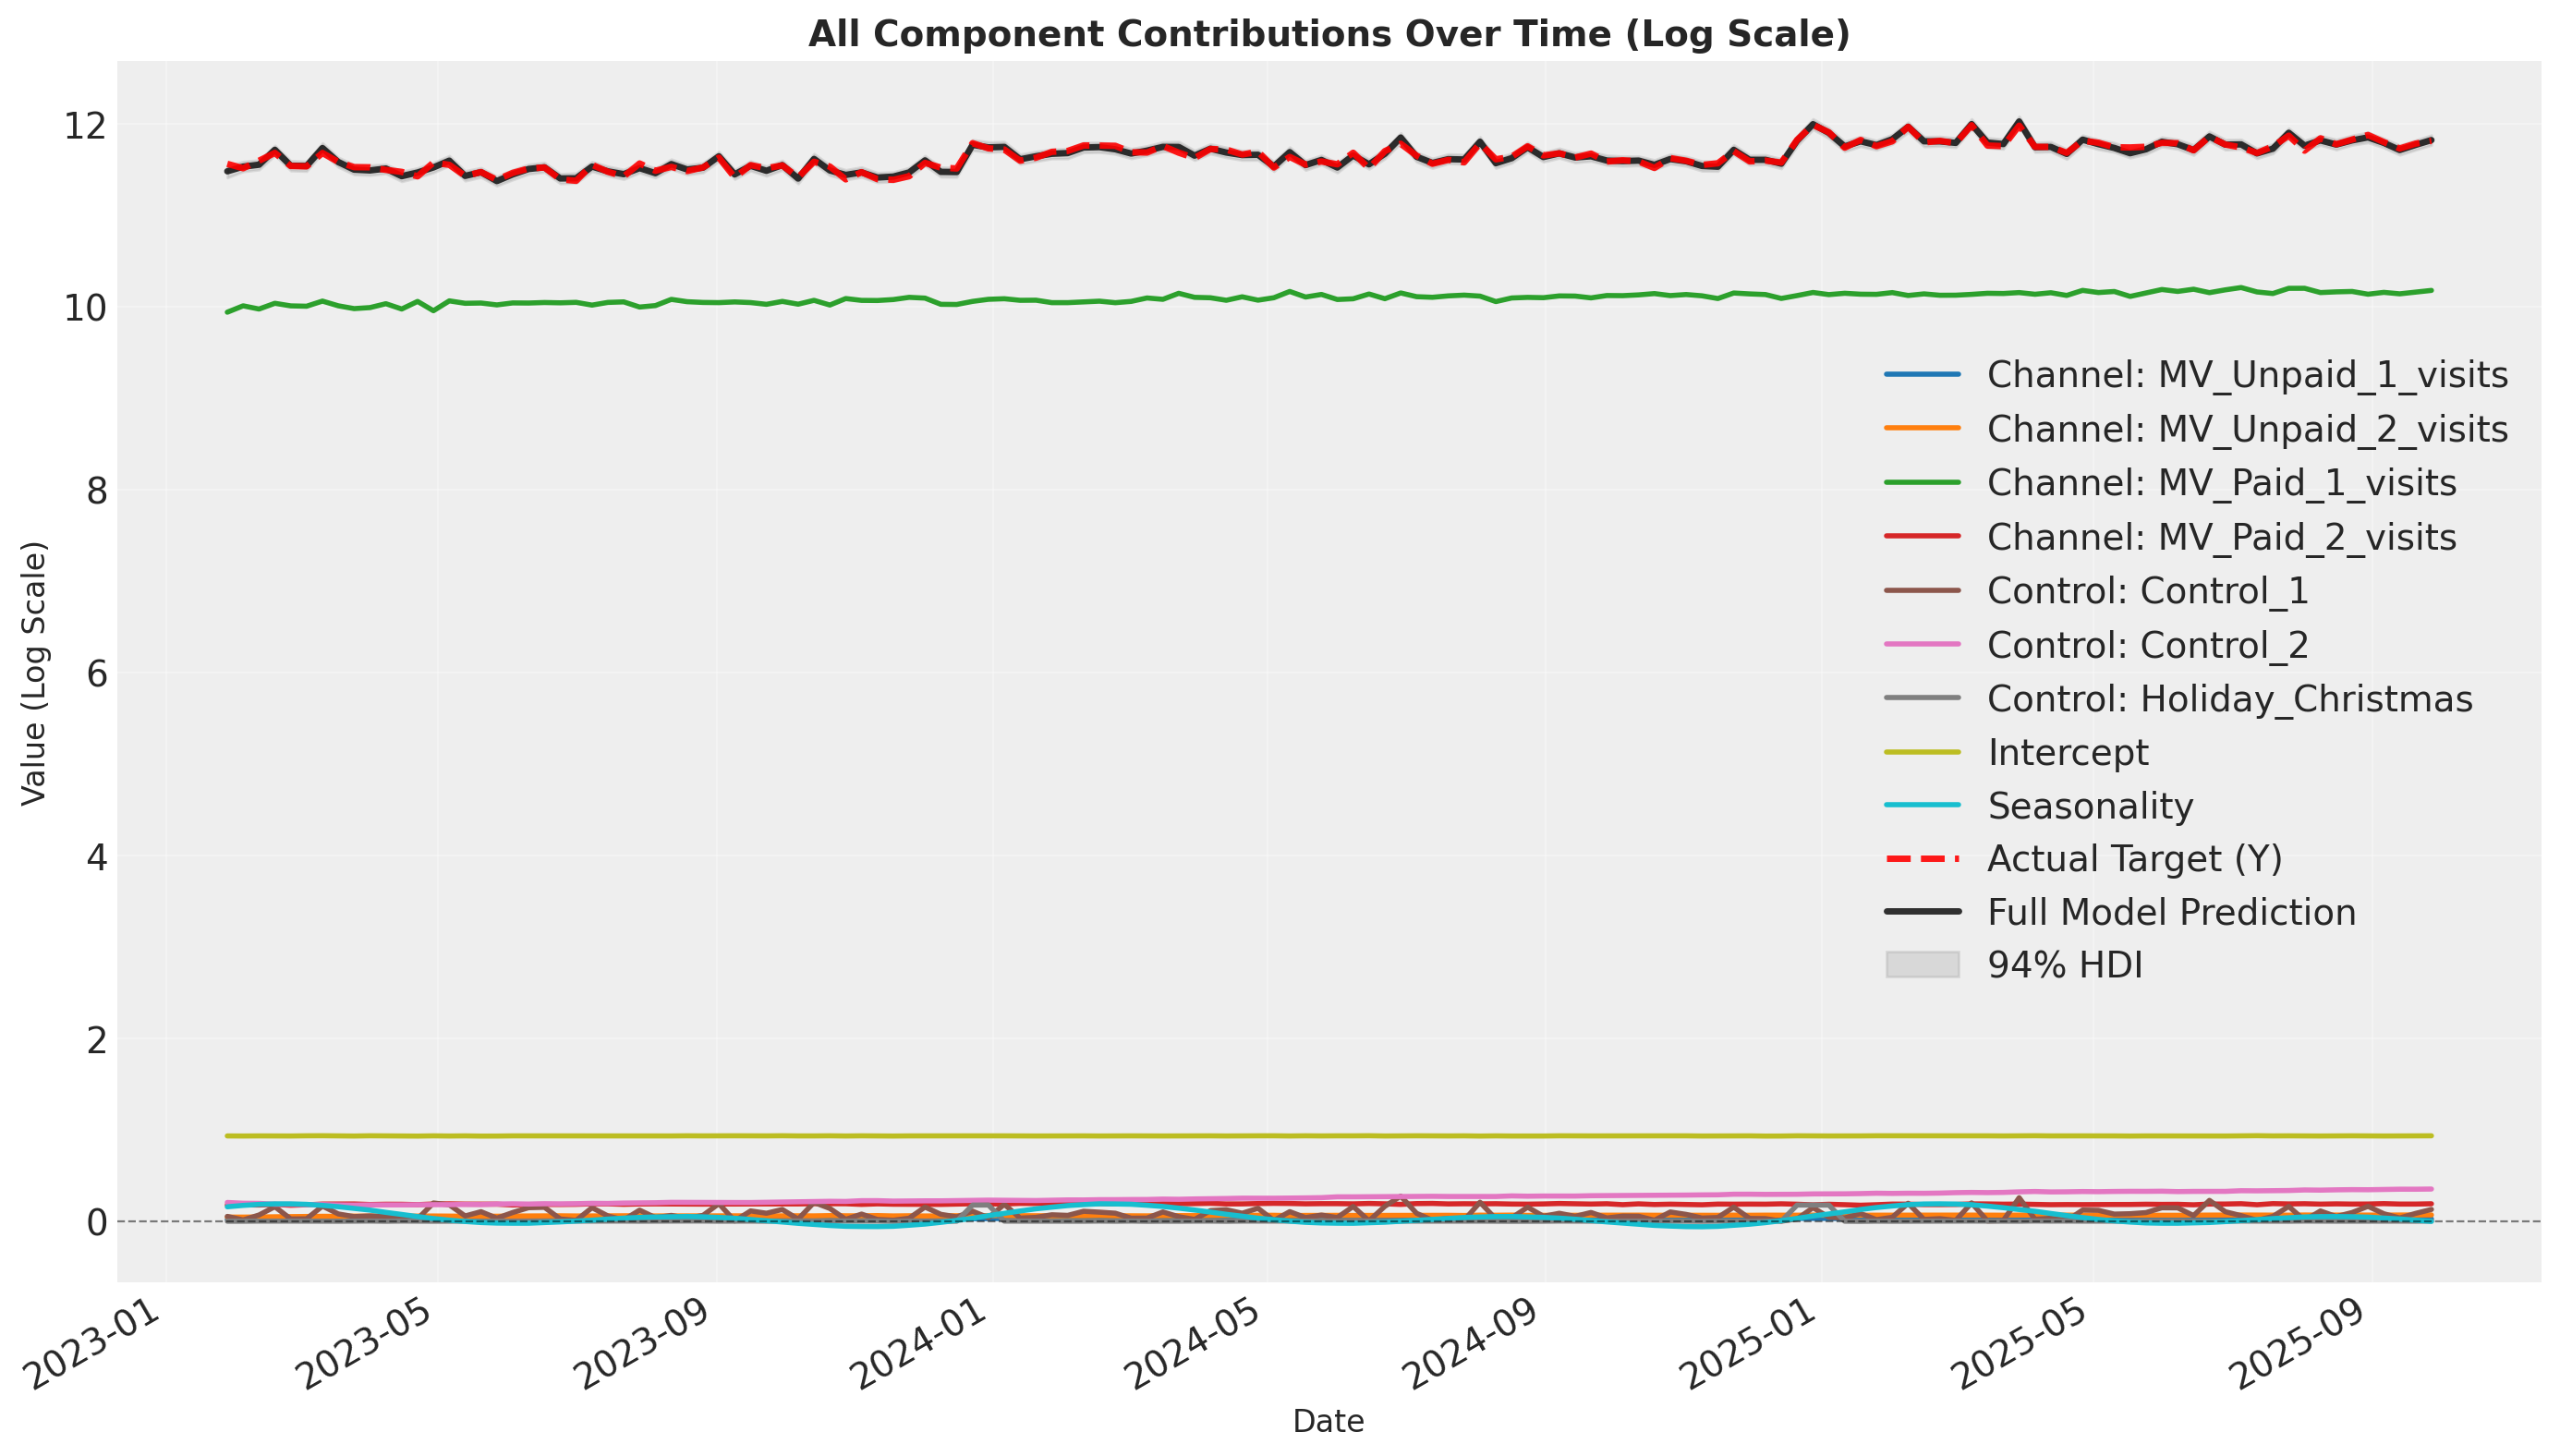

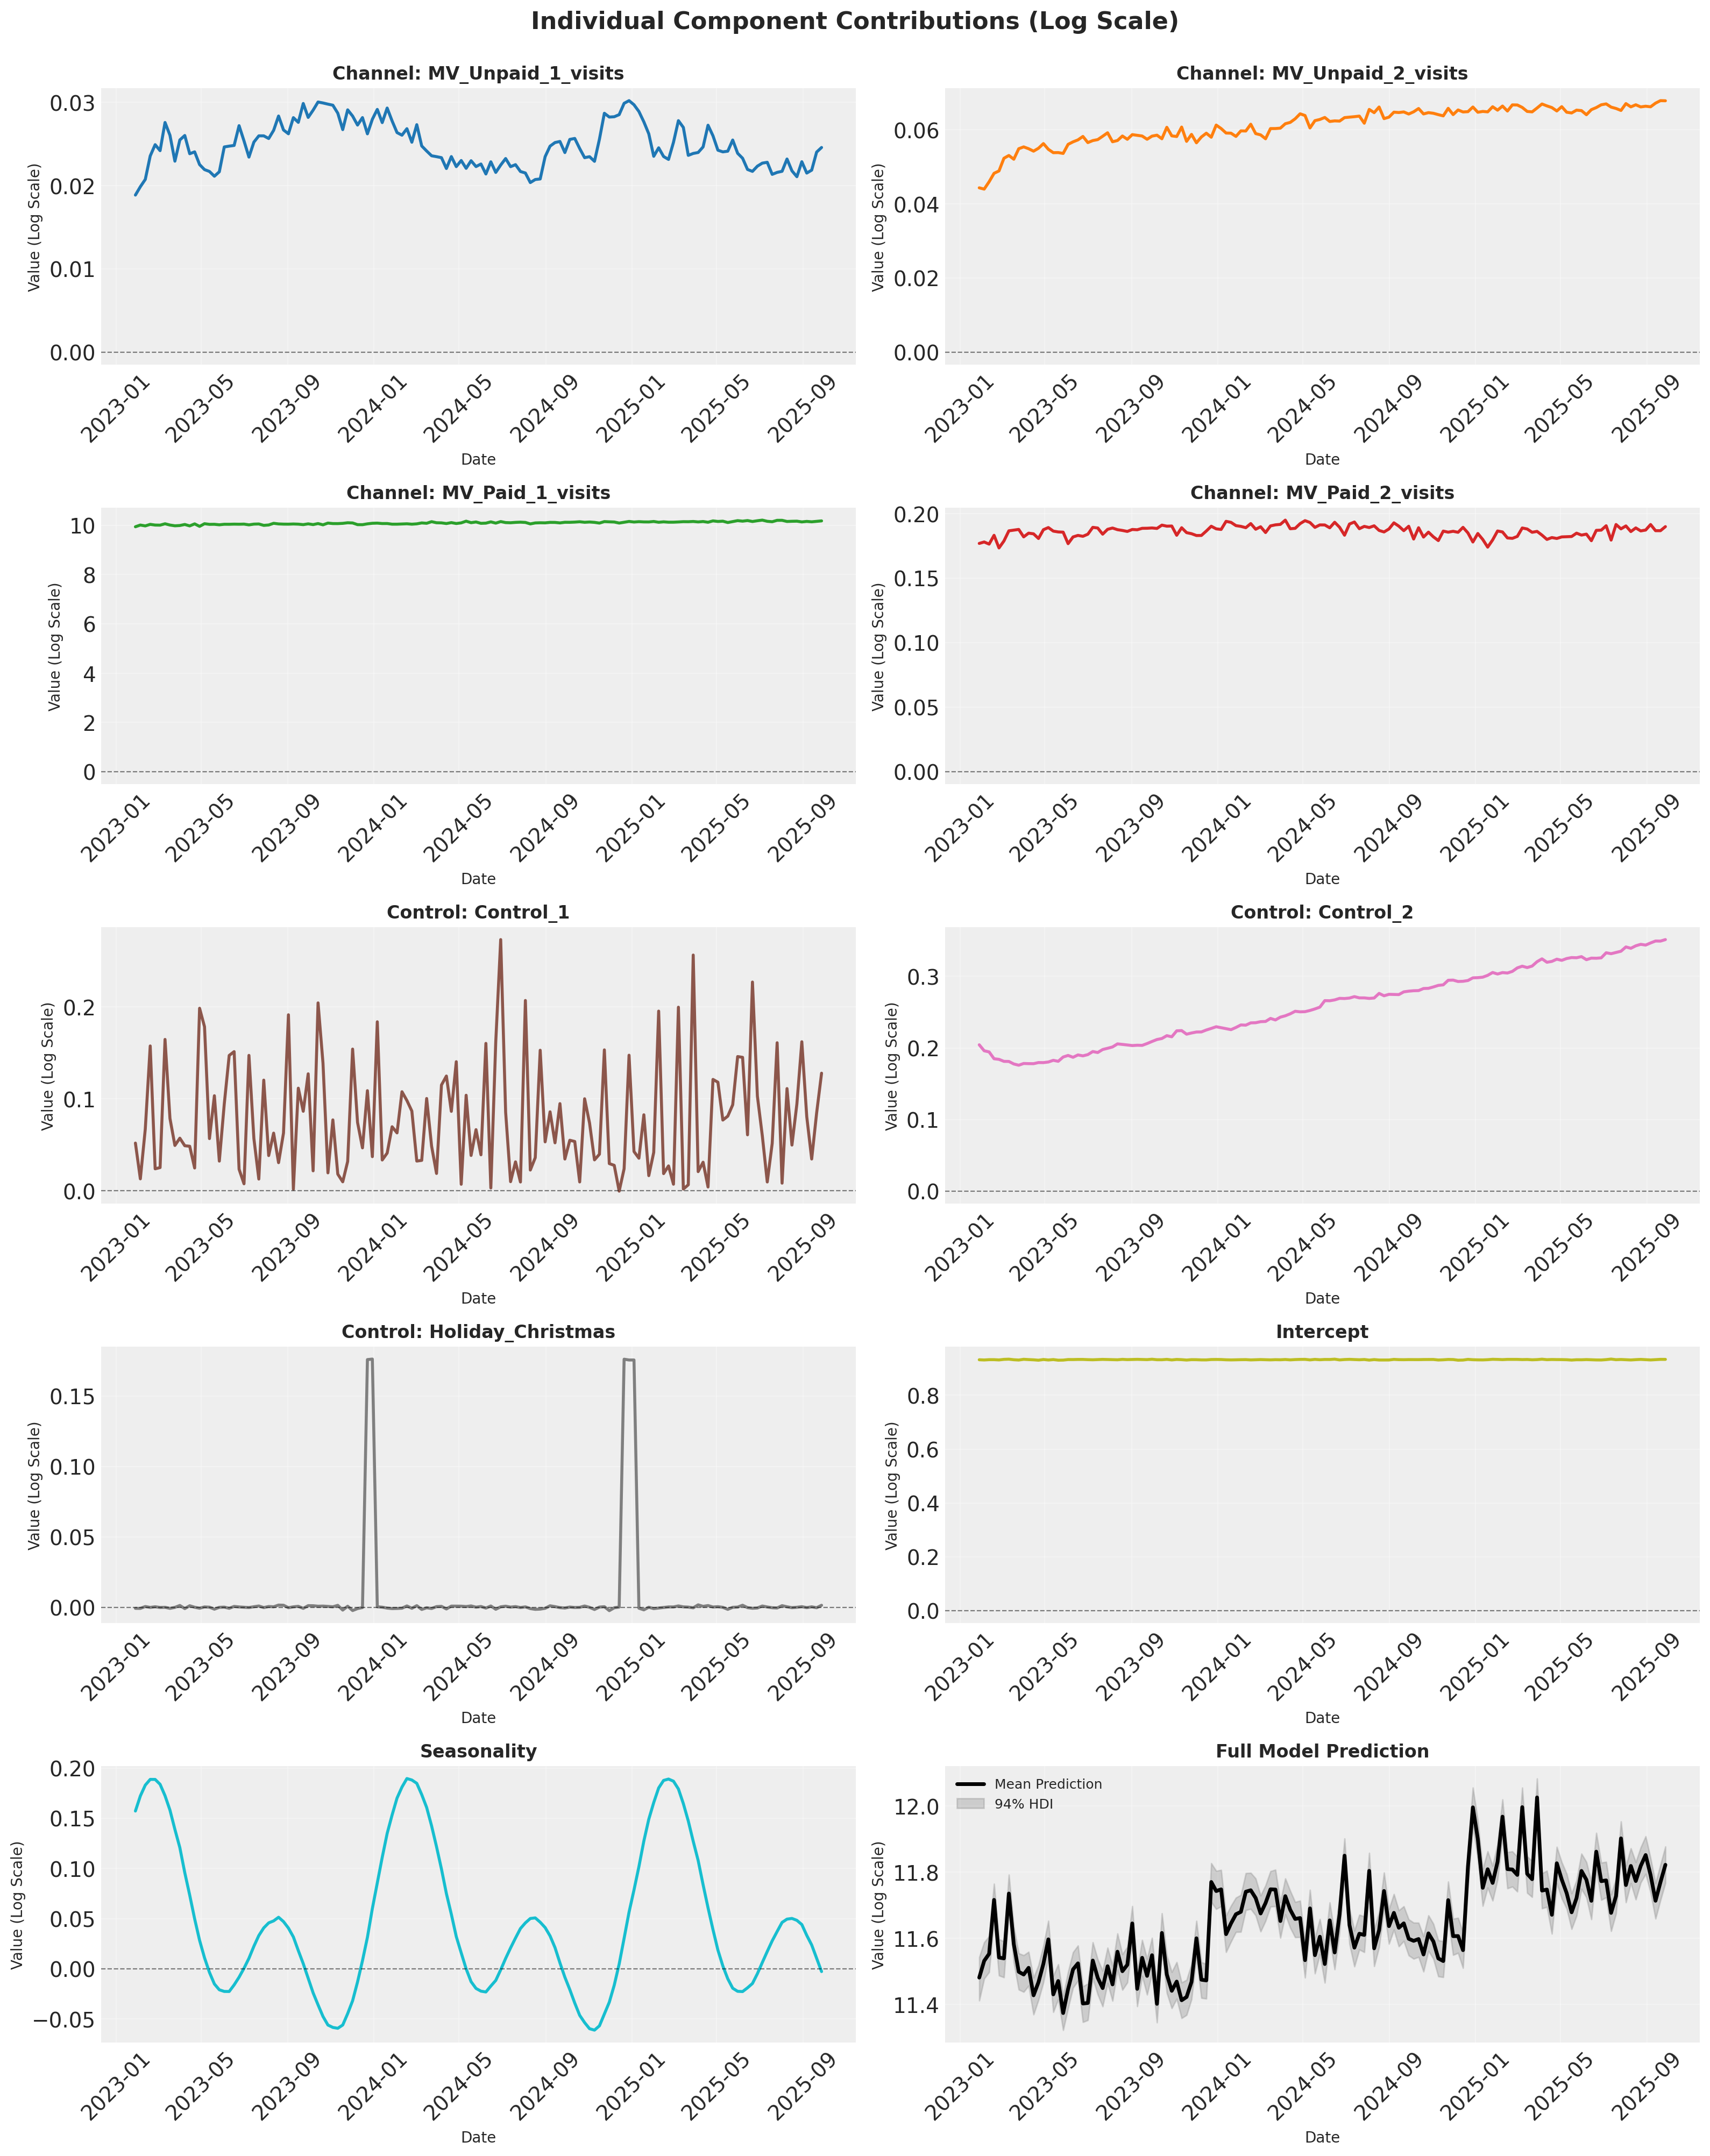

In [34]:

# Get contributions
contributions = get_individual_contributions(mmm, data, channel_cols=channel_cols, control_cols=control_cols, random_seed=seed)

# Plot with predictions (default)
fig_combined, fig_individual = plot_all_contributions(contributions, mmm=mmm, data=data)

# Get ROAS

In [35]:
# Step 1: Calculate ROAS with the new function using date range and spend mapping
roas_results_all = calculate_roas(
    contributions=contributions,
    data=data,
    channel_cols=paid_channel_names,  #  Only paid channels
    # date_start='2019-06-09',  # Replace with your desired start date
    # date_end='2022-11-27',    # Replace with your desired end date
    target_column='y',
    spend_mapping=spend_mapping  # NEW: Pass the spend mapping
)
# Step 2: Display the results
print("=" * 80)
print("ROAS CALCULATION RESULTS")
print("=" * 80)
print("\nROAS by Channel:")
print("-" * 40)
for channel, roas in roas_results_all['roas'].items():
    print(f"  {channel}: {roas:.4f} (${roas:.2f} revenue per $1 spent)")

print("\n\nTotal Spend by Channel:")
print("-" * 40)
for channel, spend in roas_results_all['spend'].items():
    print(f"  {channel}: ${spend:,.2f}")

print("\n\nTotal Adjusted Contribution by Channel:")
print("-" * 40)
for channel, contrib in roas_results_all['adjusted_contributions_channels'].items():
    total_contrib = np.sum(contrib)
    print(f"  {channel}: ${total_contrib:,.2f}")

print("\n\nVerification - Sum of ALL Adjusted Contributions:")
print("-" * 40)
period_start = roas_results_all['period']['start']
period_end = roas_results_all['period']['end']
sum_all_adjusted = sum([np.sum(contrib) for contrib in roas_results_all['adjusted_contributions_all'].values()])
sum_actual_y = data.iloc[period_start:period_end+1]['y'].sum()
print(f"  Sum of all adjusted contributions: ${sum_all_adjusted:,.2f}")
print(f"  Sum of actual Y (for selected period): ${sum_actual_y:,.2f}")
print(f"  Difference: ${abs(sum_all_adjusted - sum_actual_y):,.2f}")
print(f"  Match: {'YES ✓' if abs(sum_all_adjusted - sum_actual_y) < 0.01 else 'NO ✗'}")

print("\n" + "=" * 80)

ROAS CALCULATION RESULTS

ROAS by Channel:
----------------------------------------
  MV_Paid_1_visits: 33.1671 ($33.17 revenue per $1 spent)
  MV_Paid_2_visits: 3.2000 ($3.20 revenue per $1 spent)


Total Spend by Channel:
----------------------------------------
  MV_Paid_1_visits: $420,522.79
  MV_Paid_2_visits: $78,413.29


Total Adjusted Contribution by Channel:
----------------------------------------
  MV_Paid_1_visits: $13,947,523.11
  MV_Paid_2_visits: $250,919.19


Verification - Sum of ALL Adjusted Contributions:
----------------------------------------
  Sum of all adjusted contributions: $16,153,613.14
  Sum of actual Y (for selected period): $16,153,613.14
  Difference: $0.00
  Match: YES ✓



In [36]:
roas_results_all["adjusted_contributions_all"].keys()

dict_keys(['channel_MV_Unpaid_1_visits', 'channel_MV_Unpaid_2_visits', 'channel_MV_Paid_1_visits', 'channel_MV_Paid_2_visits', 'control_Control_1', 'control_Control_2', 'control_Holiday_Christmas', 'intercept', 'seasonality'])

ROAS Analysis - Cumulative Period: 2023-01-28 to 2025-09-27 (140 days)

Channel ROAS Statistics:
--------------------------------------------------------------------------------
  MV_Paid_1_visits:
    - Lower bound 90% CI (5.0%): 32.73
    - Lower bound 85% CI (7.5%): 32.75
    - Median (50%): 33.20
    - Mean: 33.19
    - Upper bound 85% CI (92.5%): 33.62
    - Upper bound 90% CI (95.0%): 33.73

  MV_Paid_2_visits:
    - Lower bound 90% CI (5.0%): 3.03
    - Lower bound 85% CI (7.5%): 3.04
    - Median (50%): 3.20
    - Mean: 3.19
    - Upper bound 85% CI (92.5%): 3.31
    - Upper bound 90% CI (95.0%): 3.33




c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:561: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:597: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:638: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:1597: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:709: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:767: UserWarning: The figure layout has changed to 

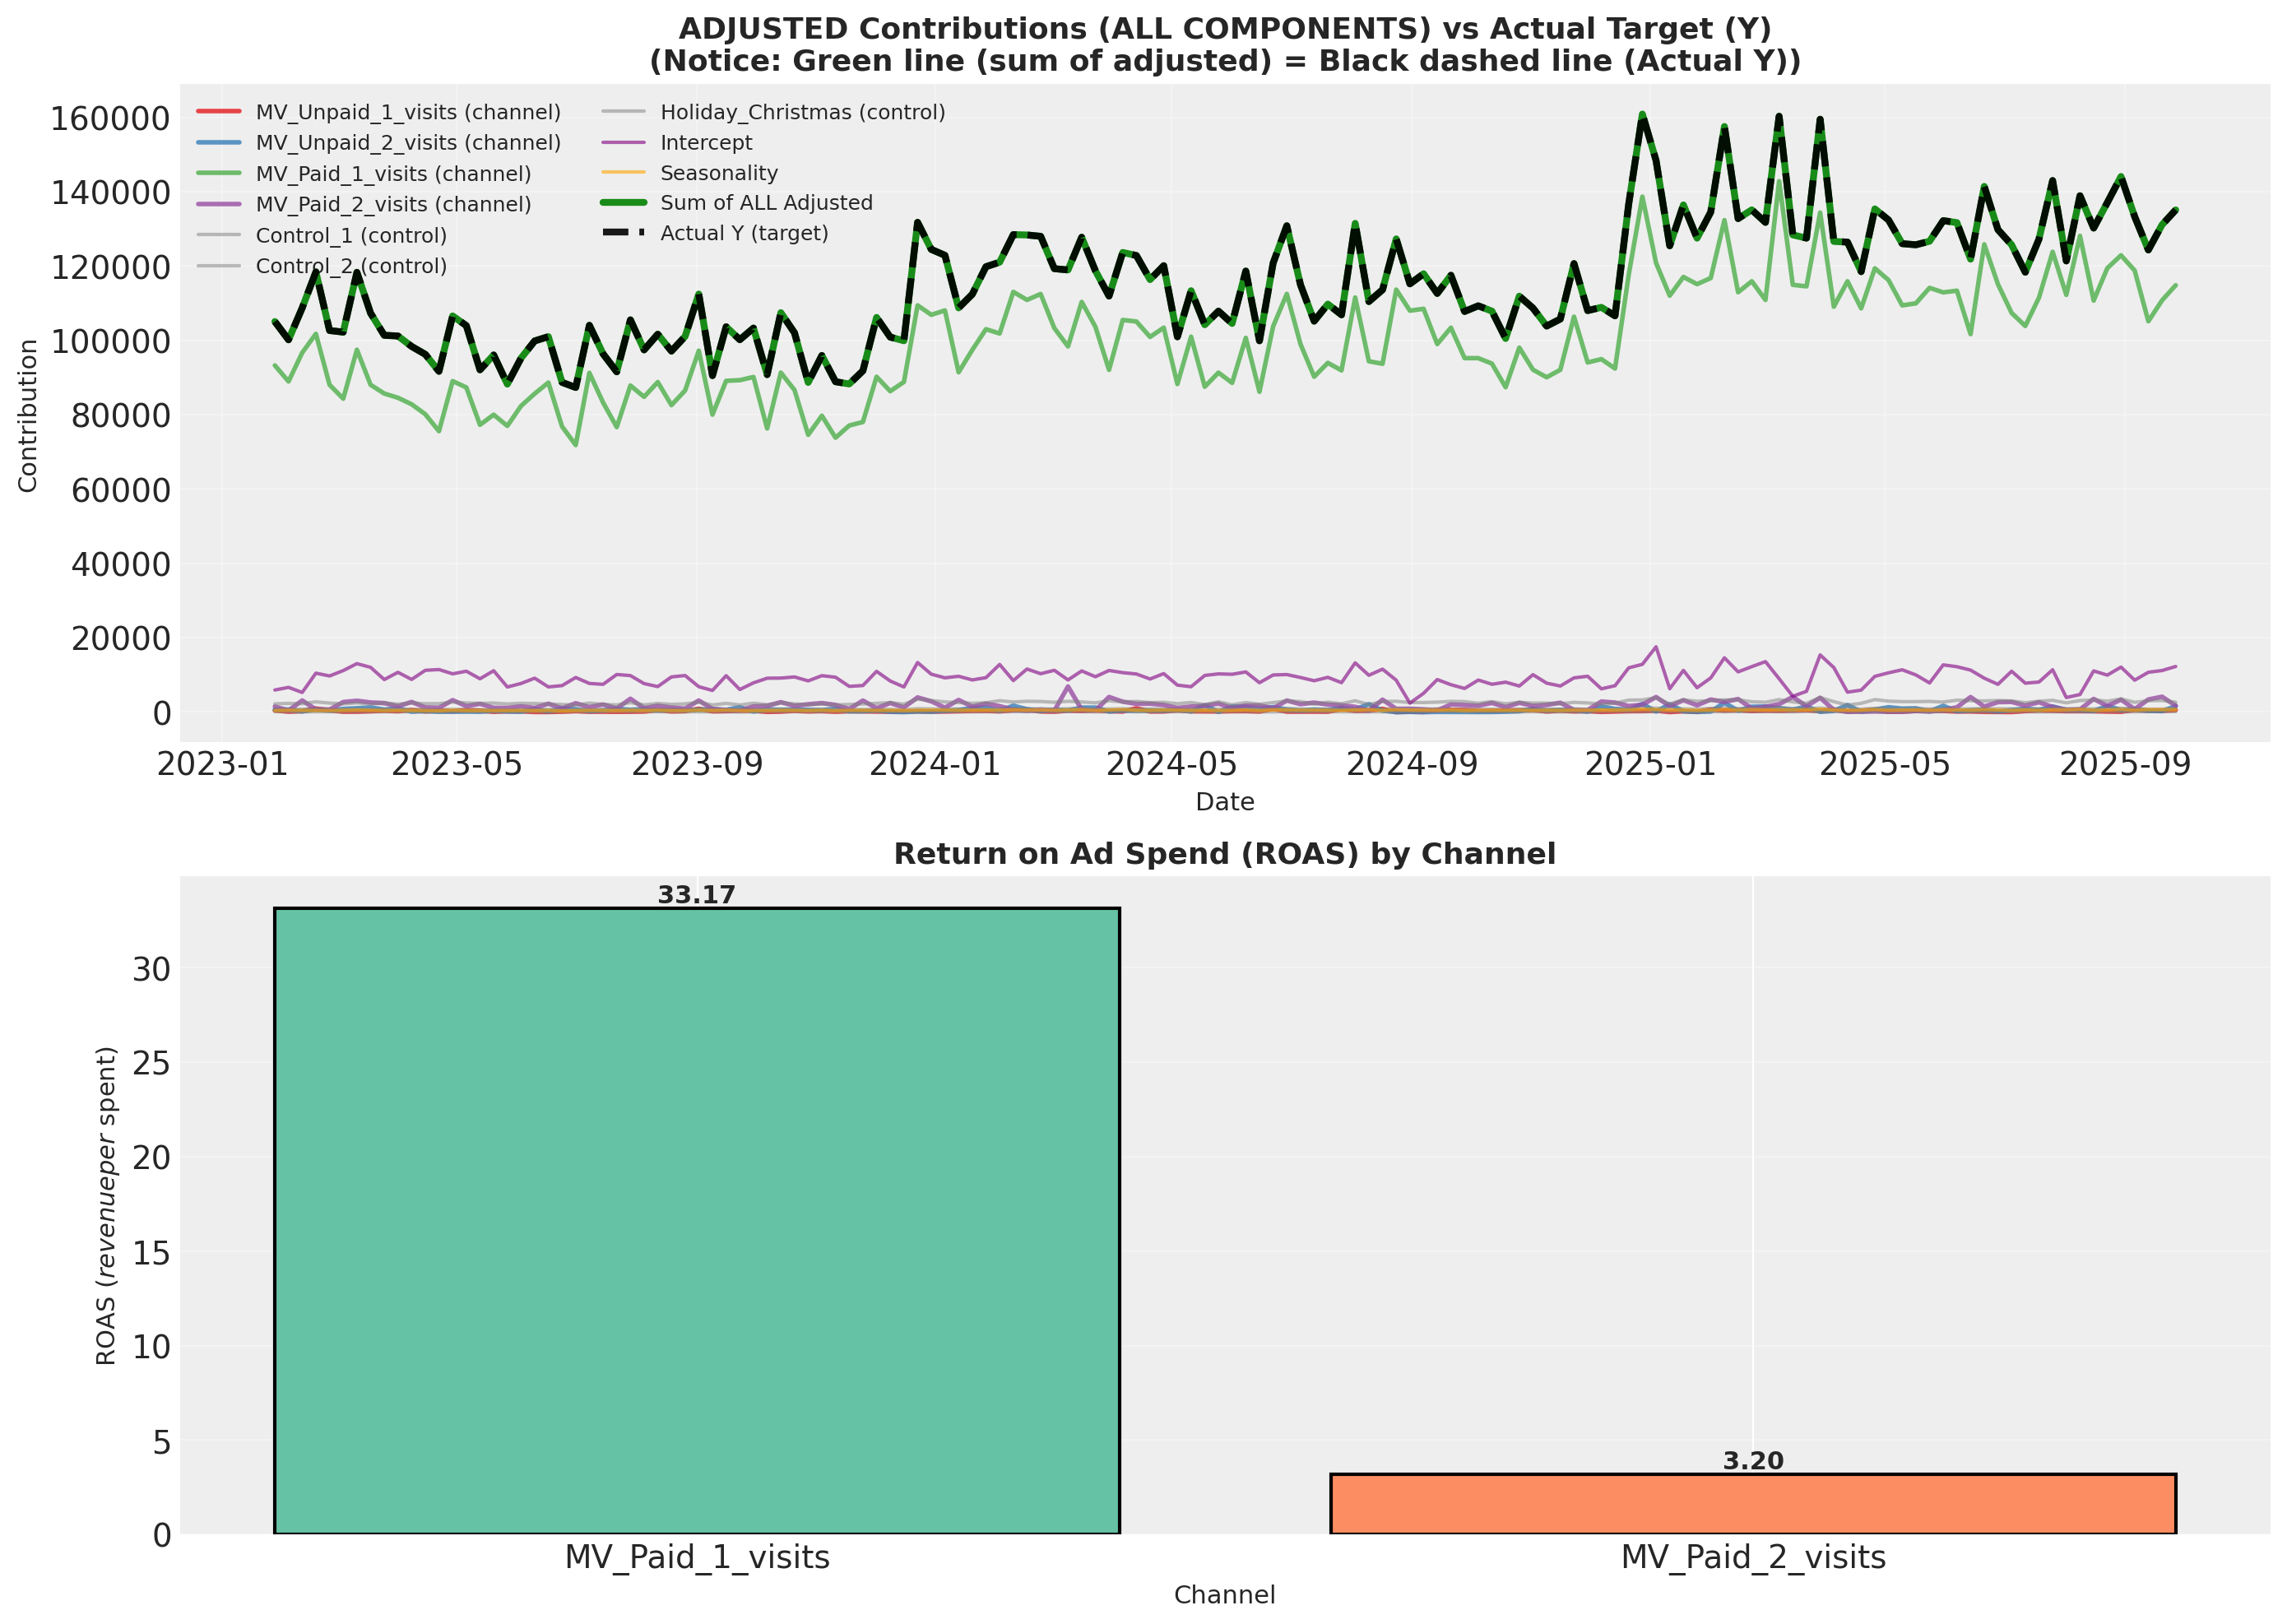

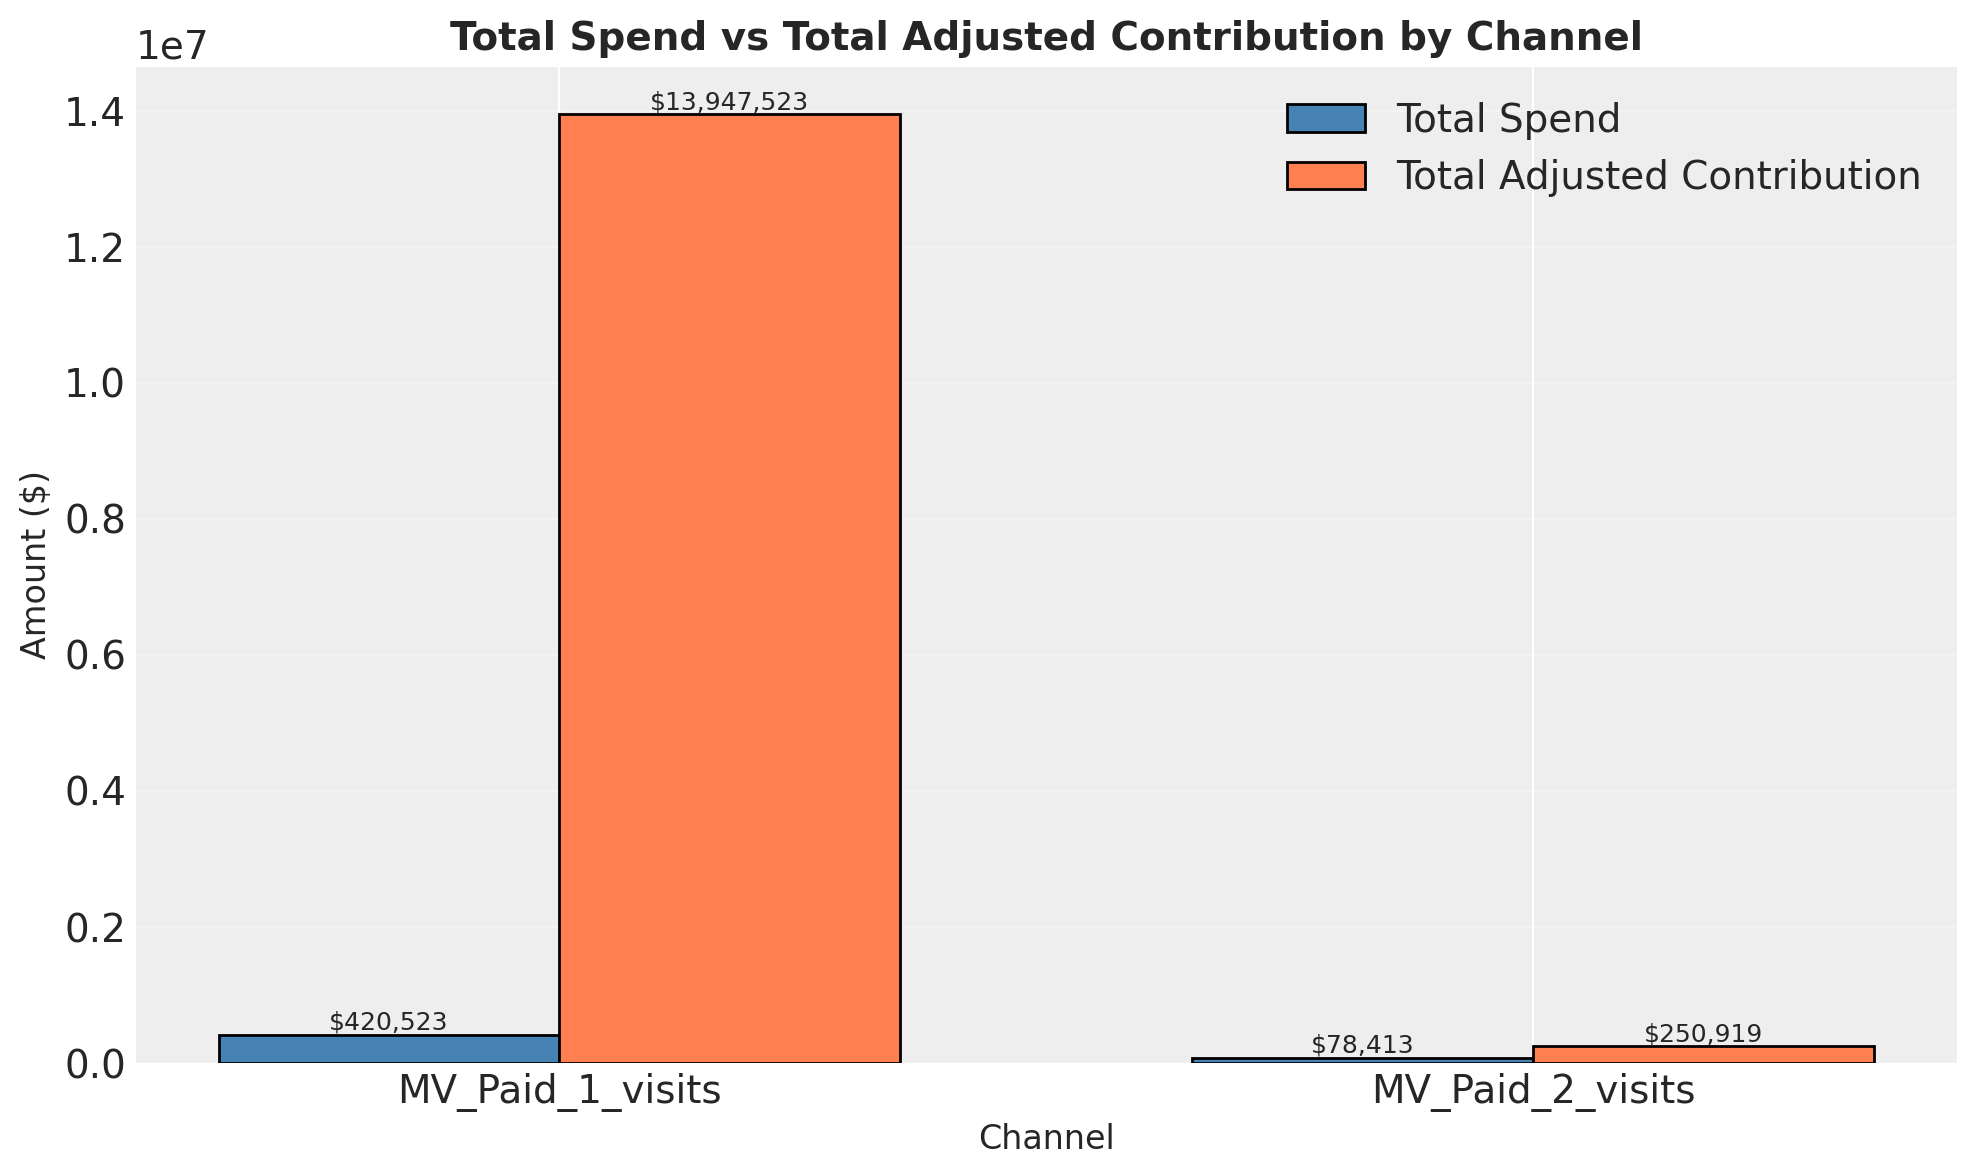

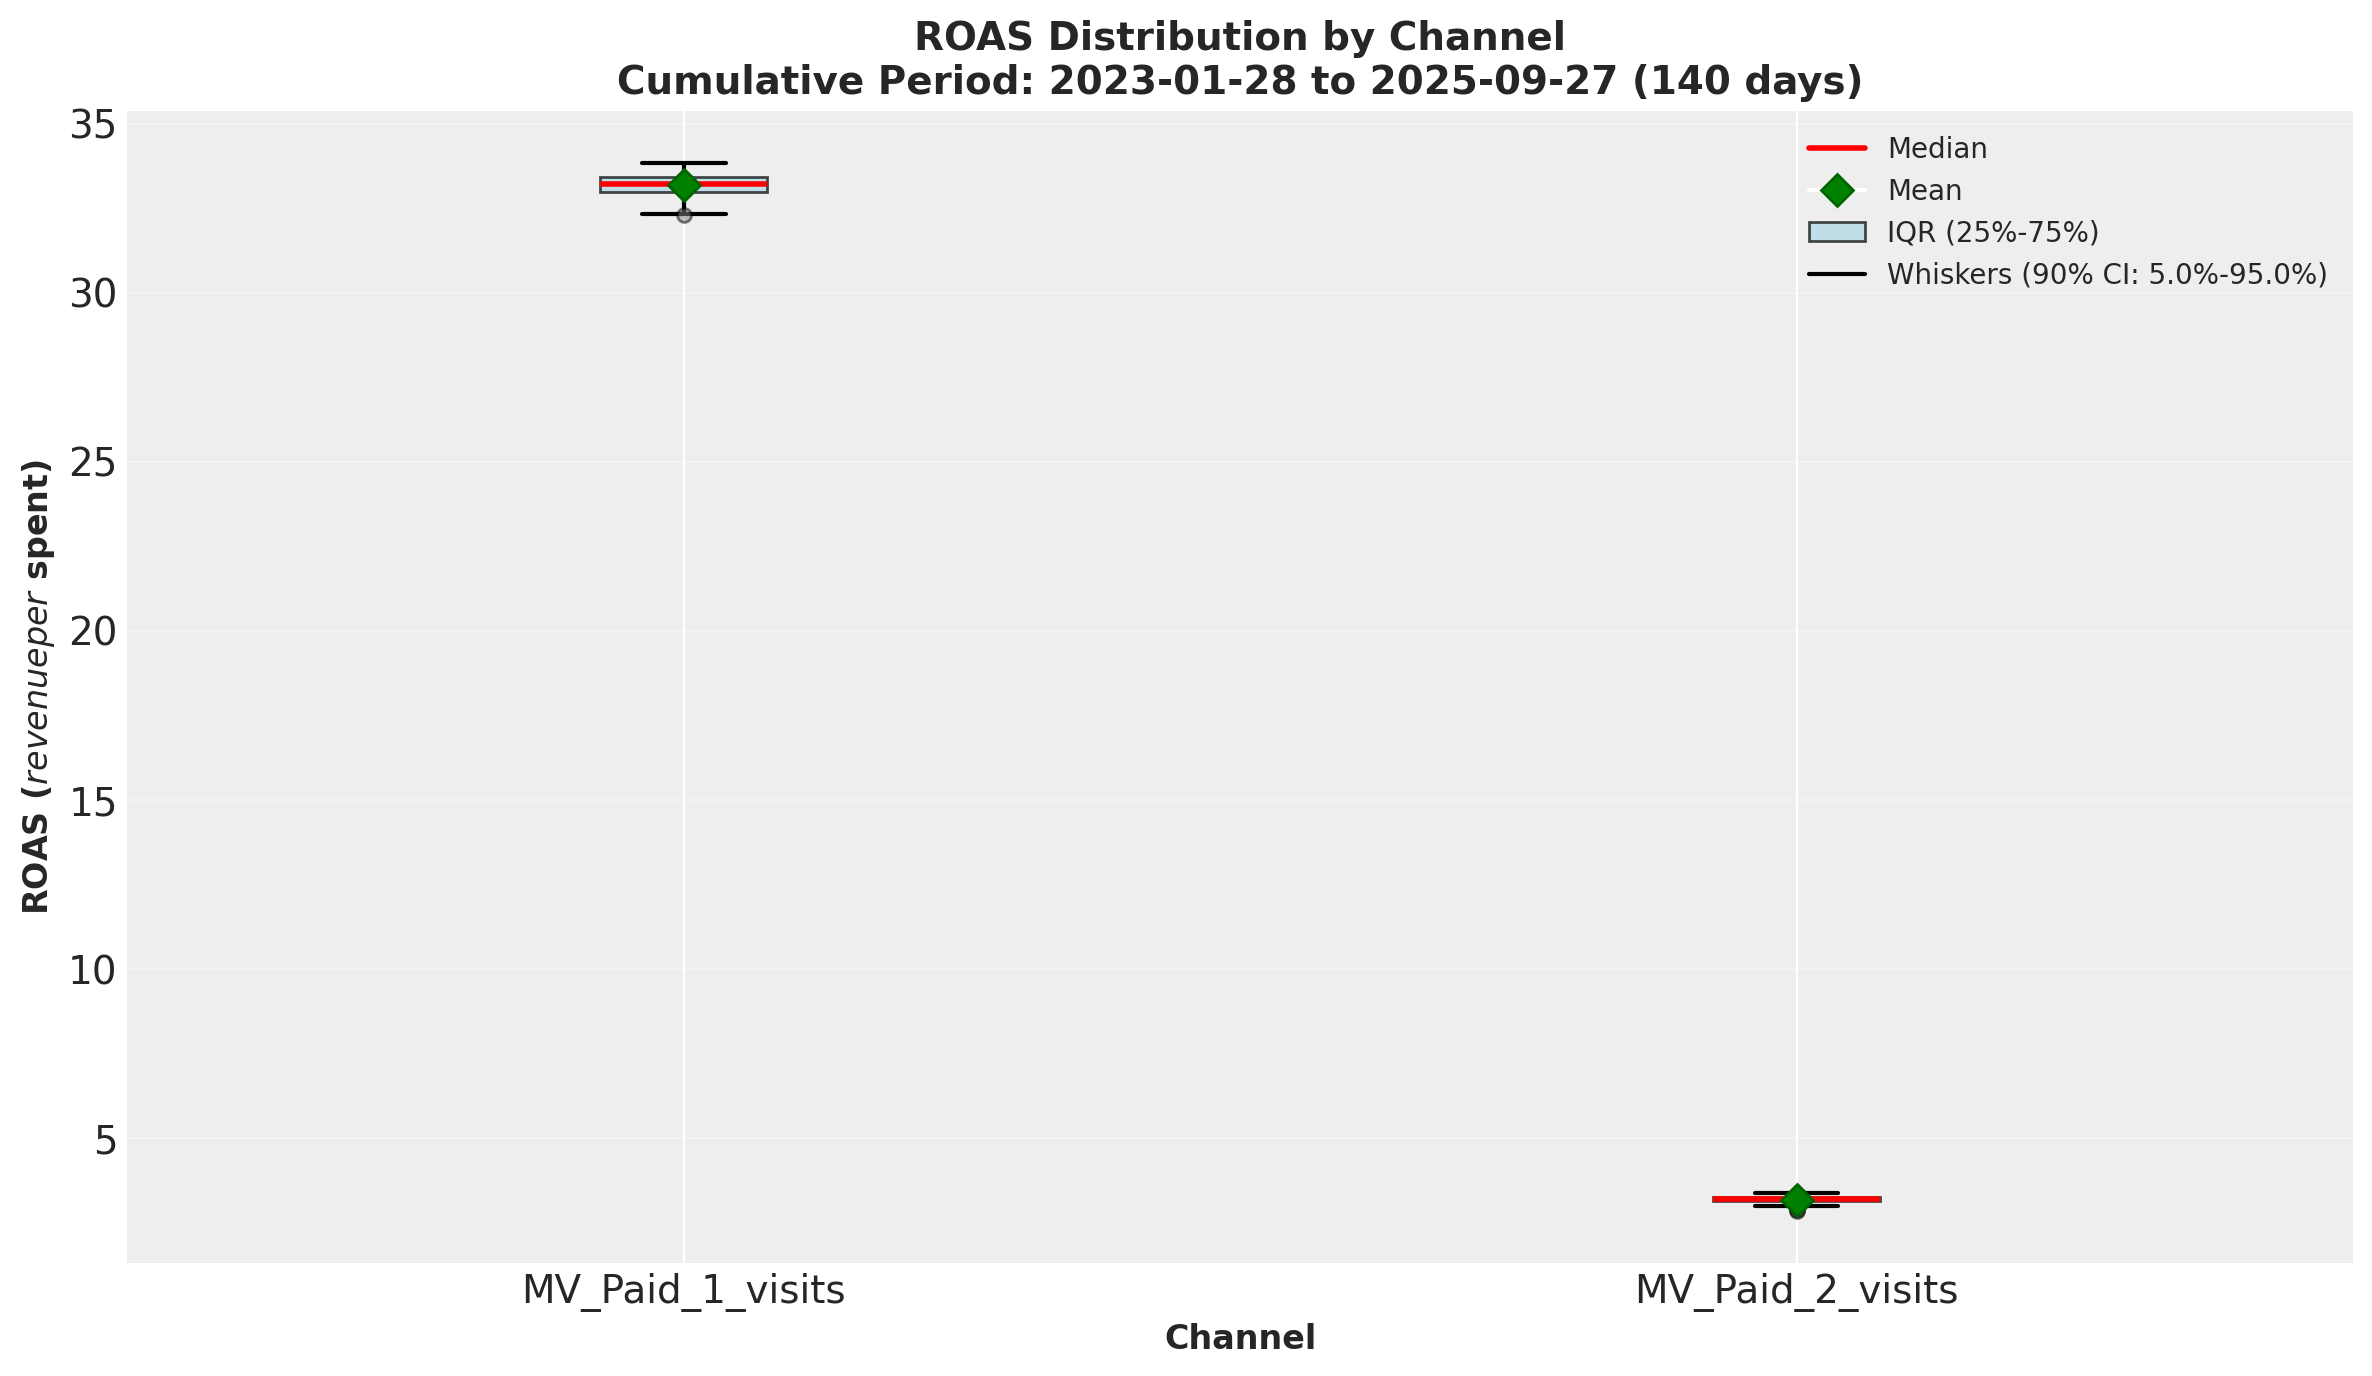

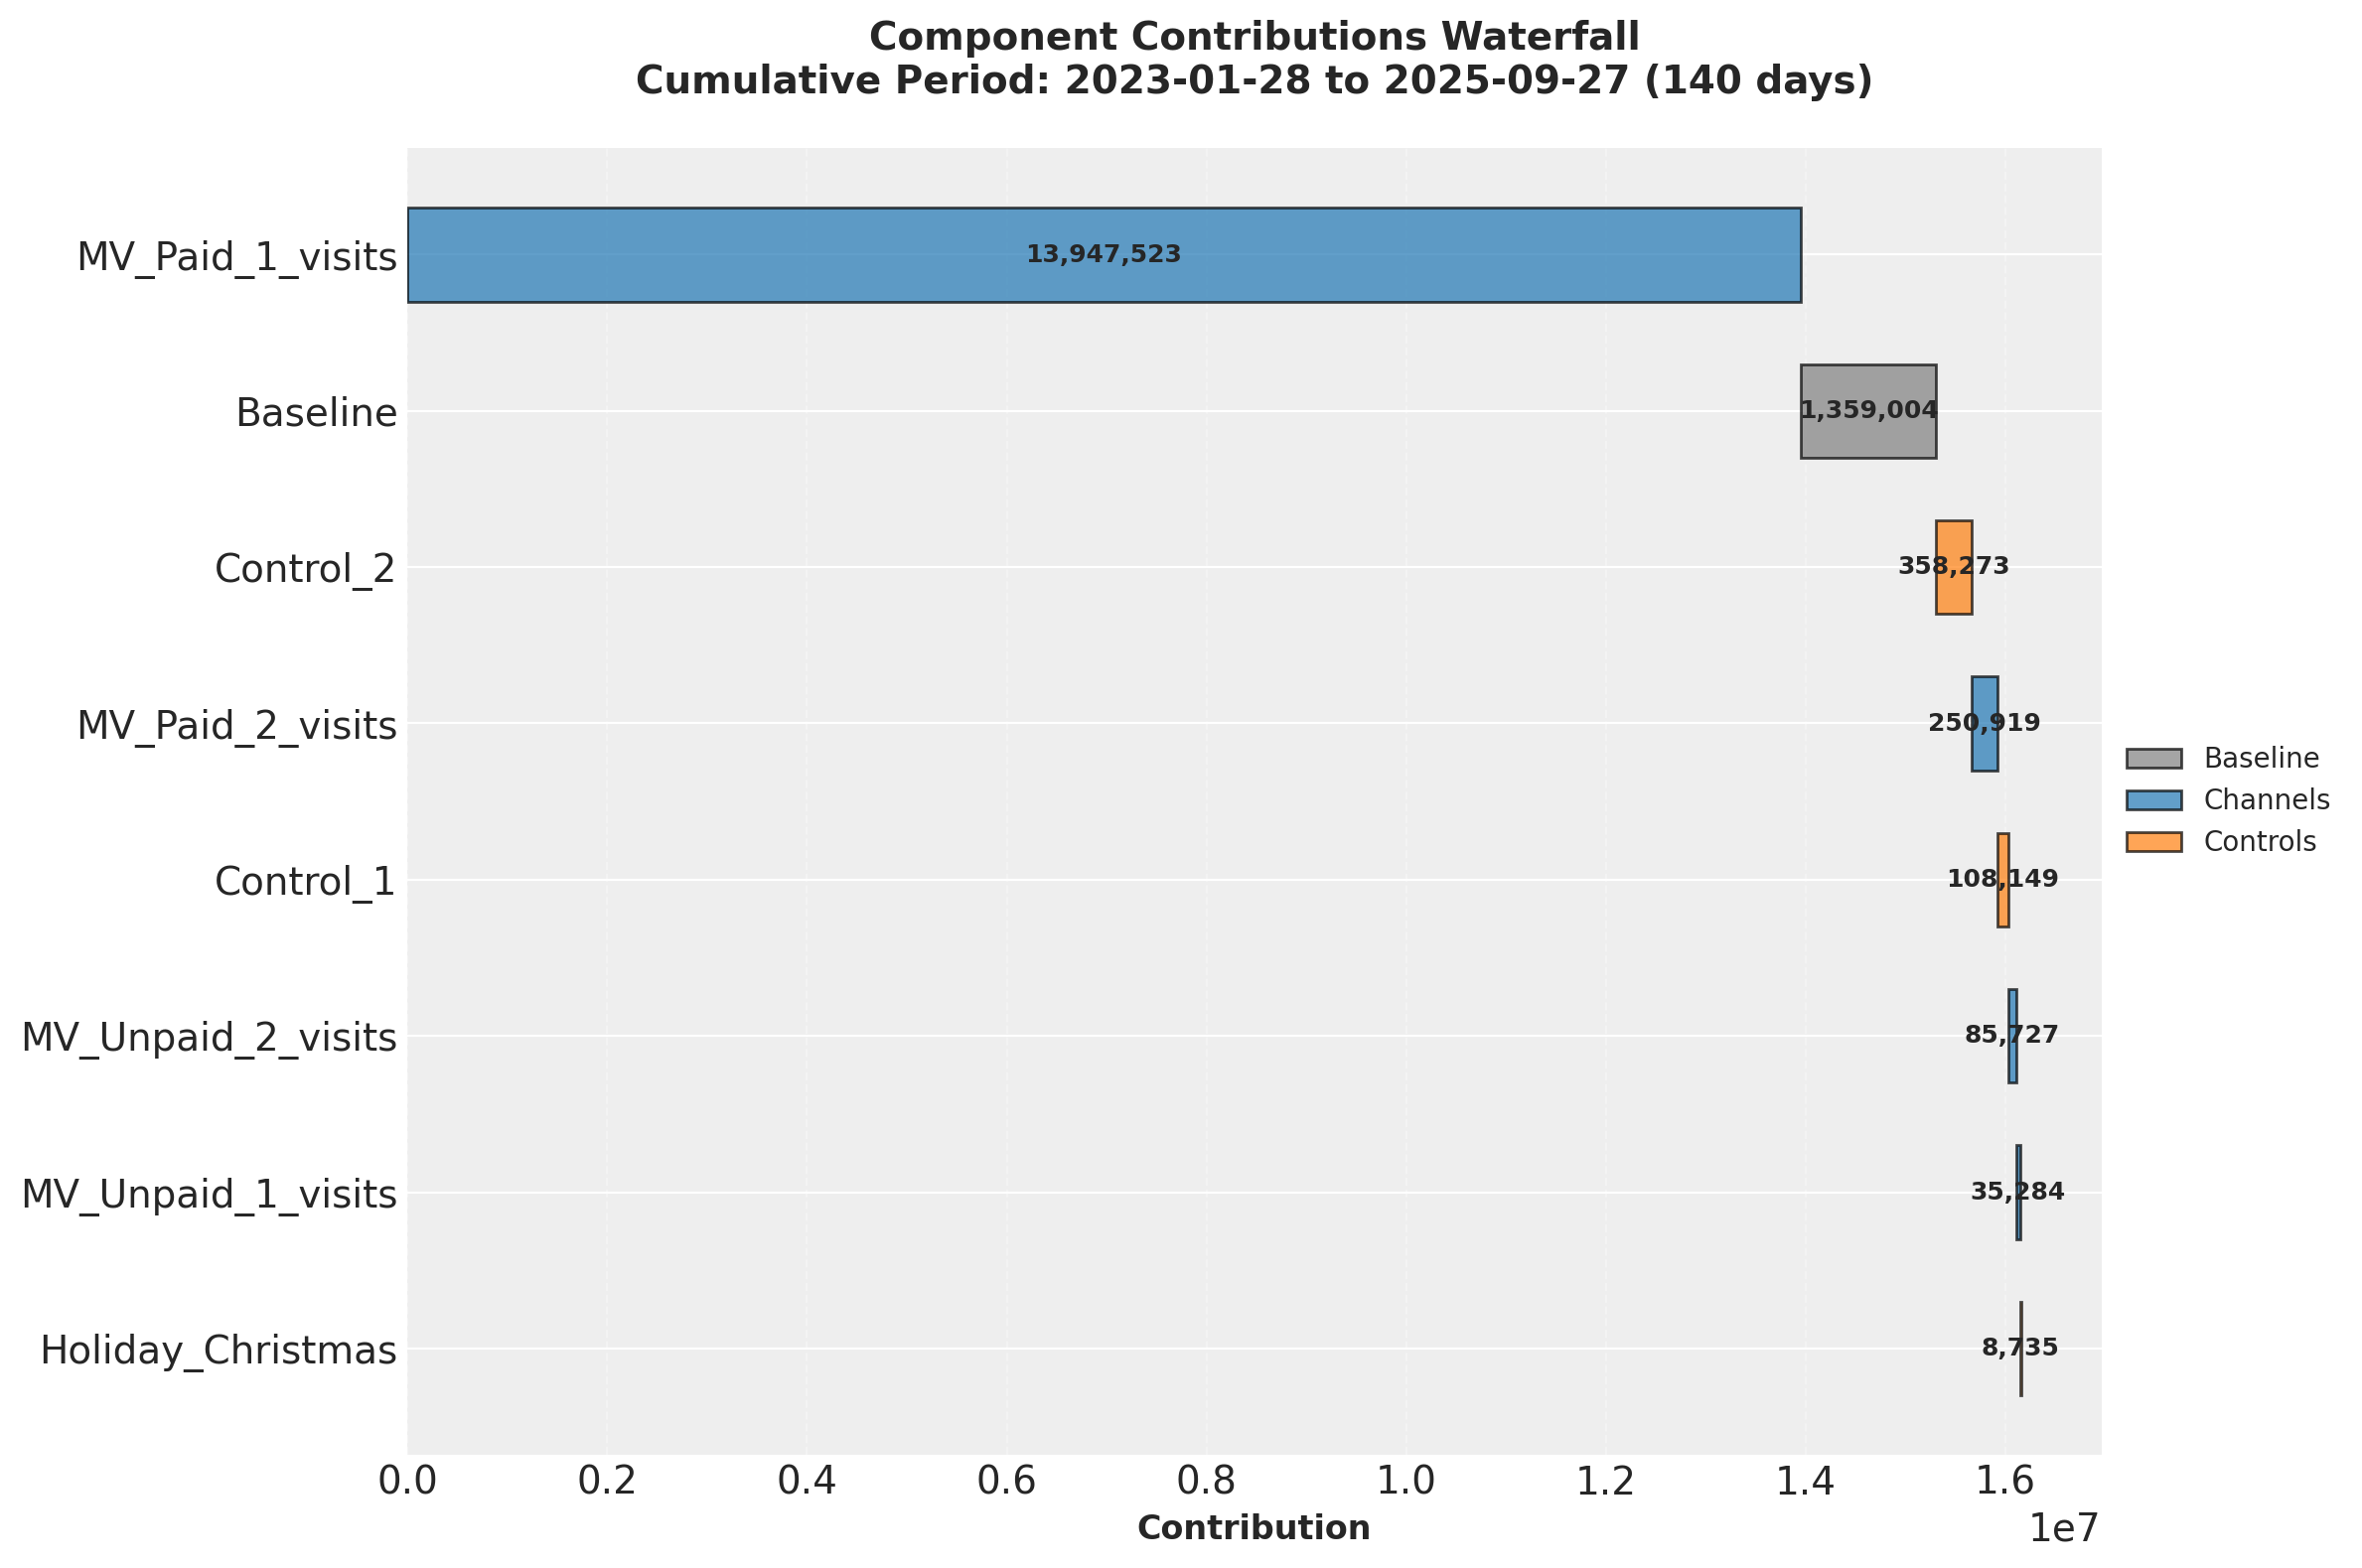

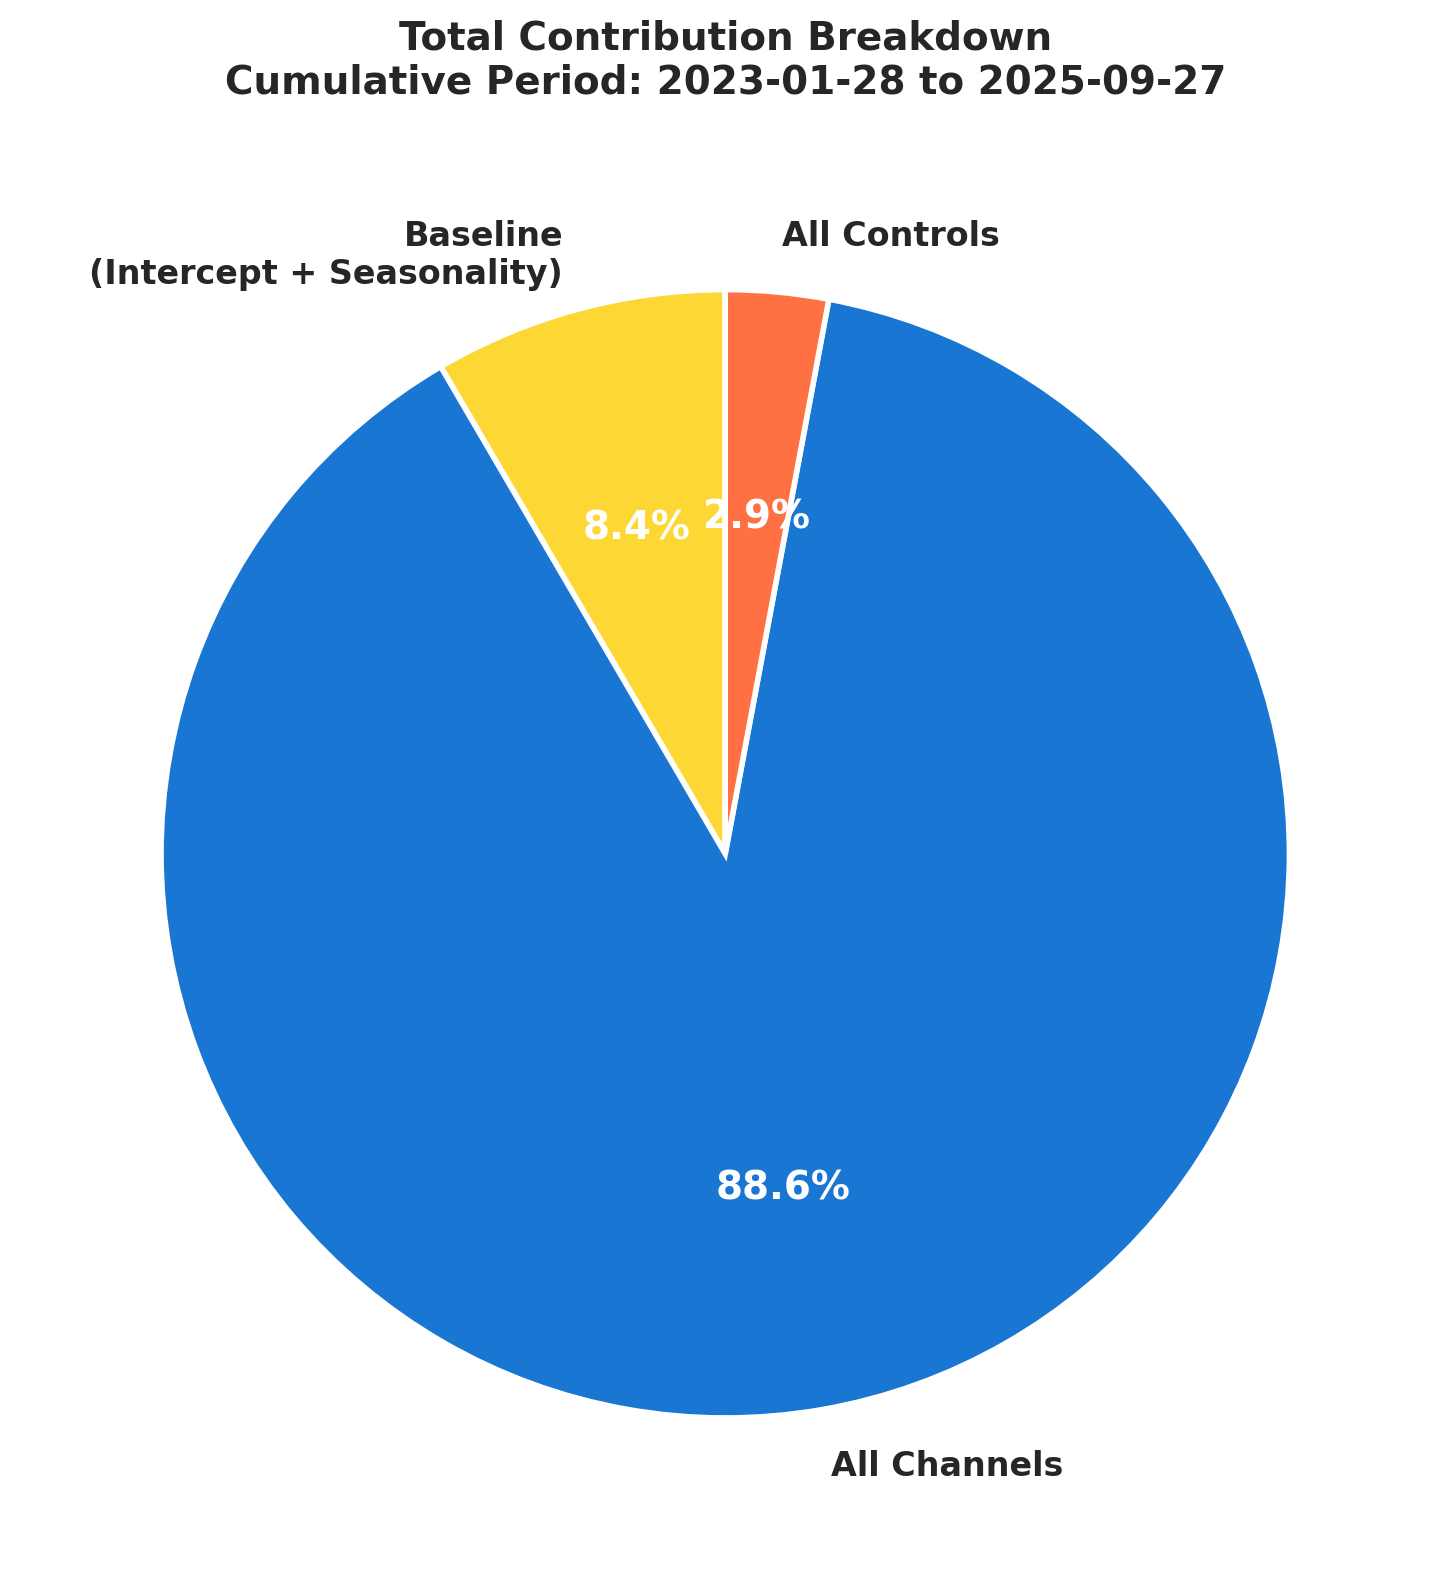

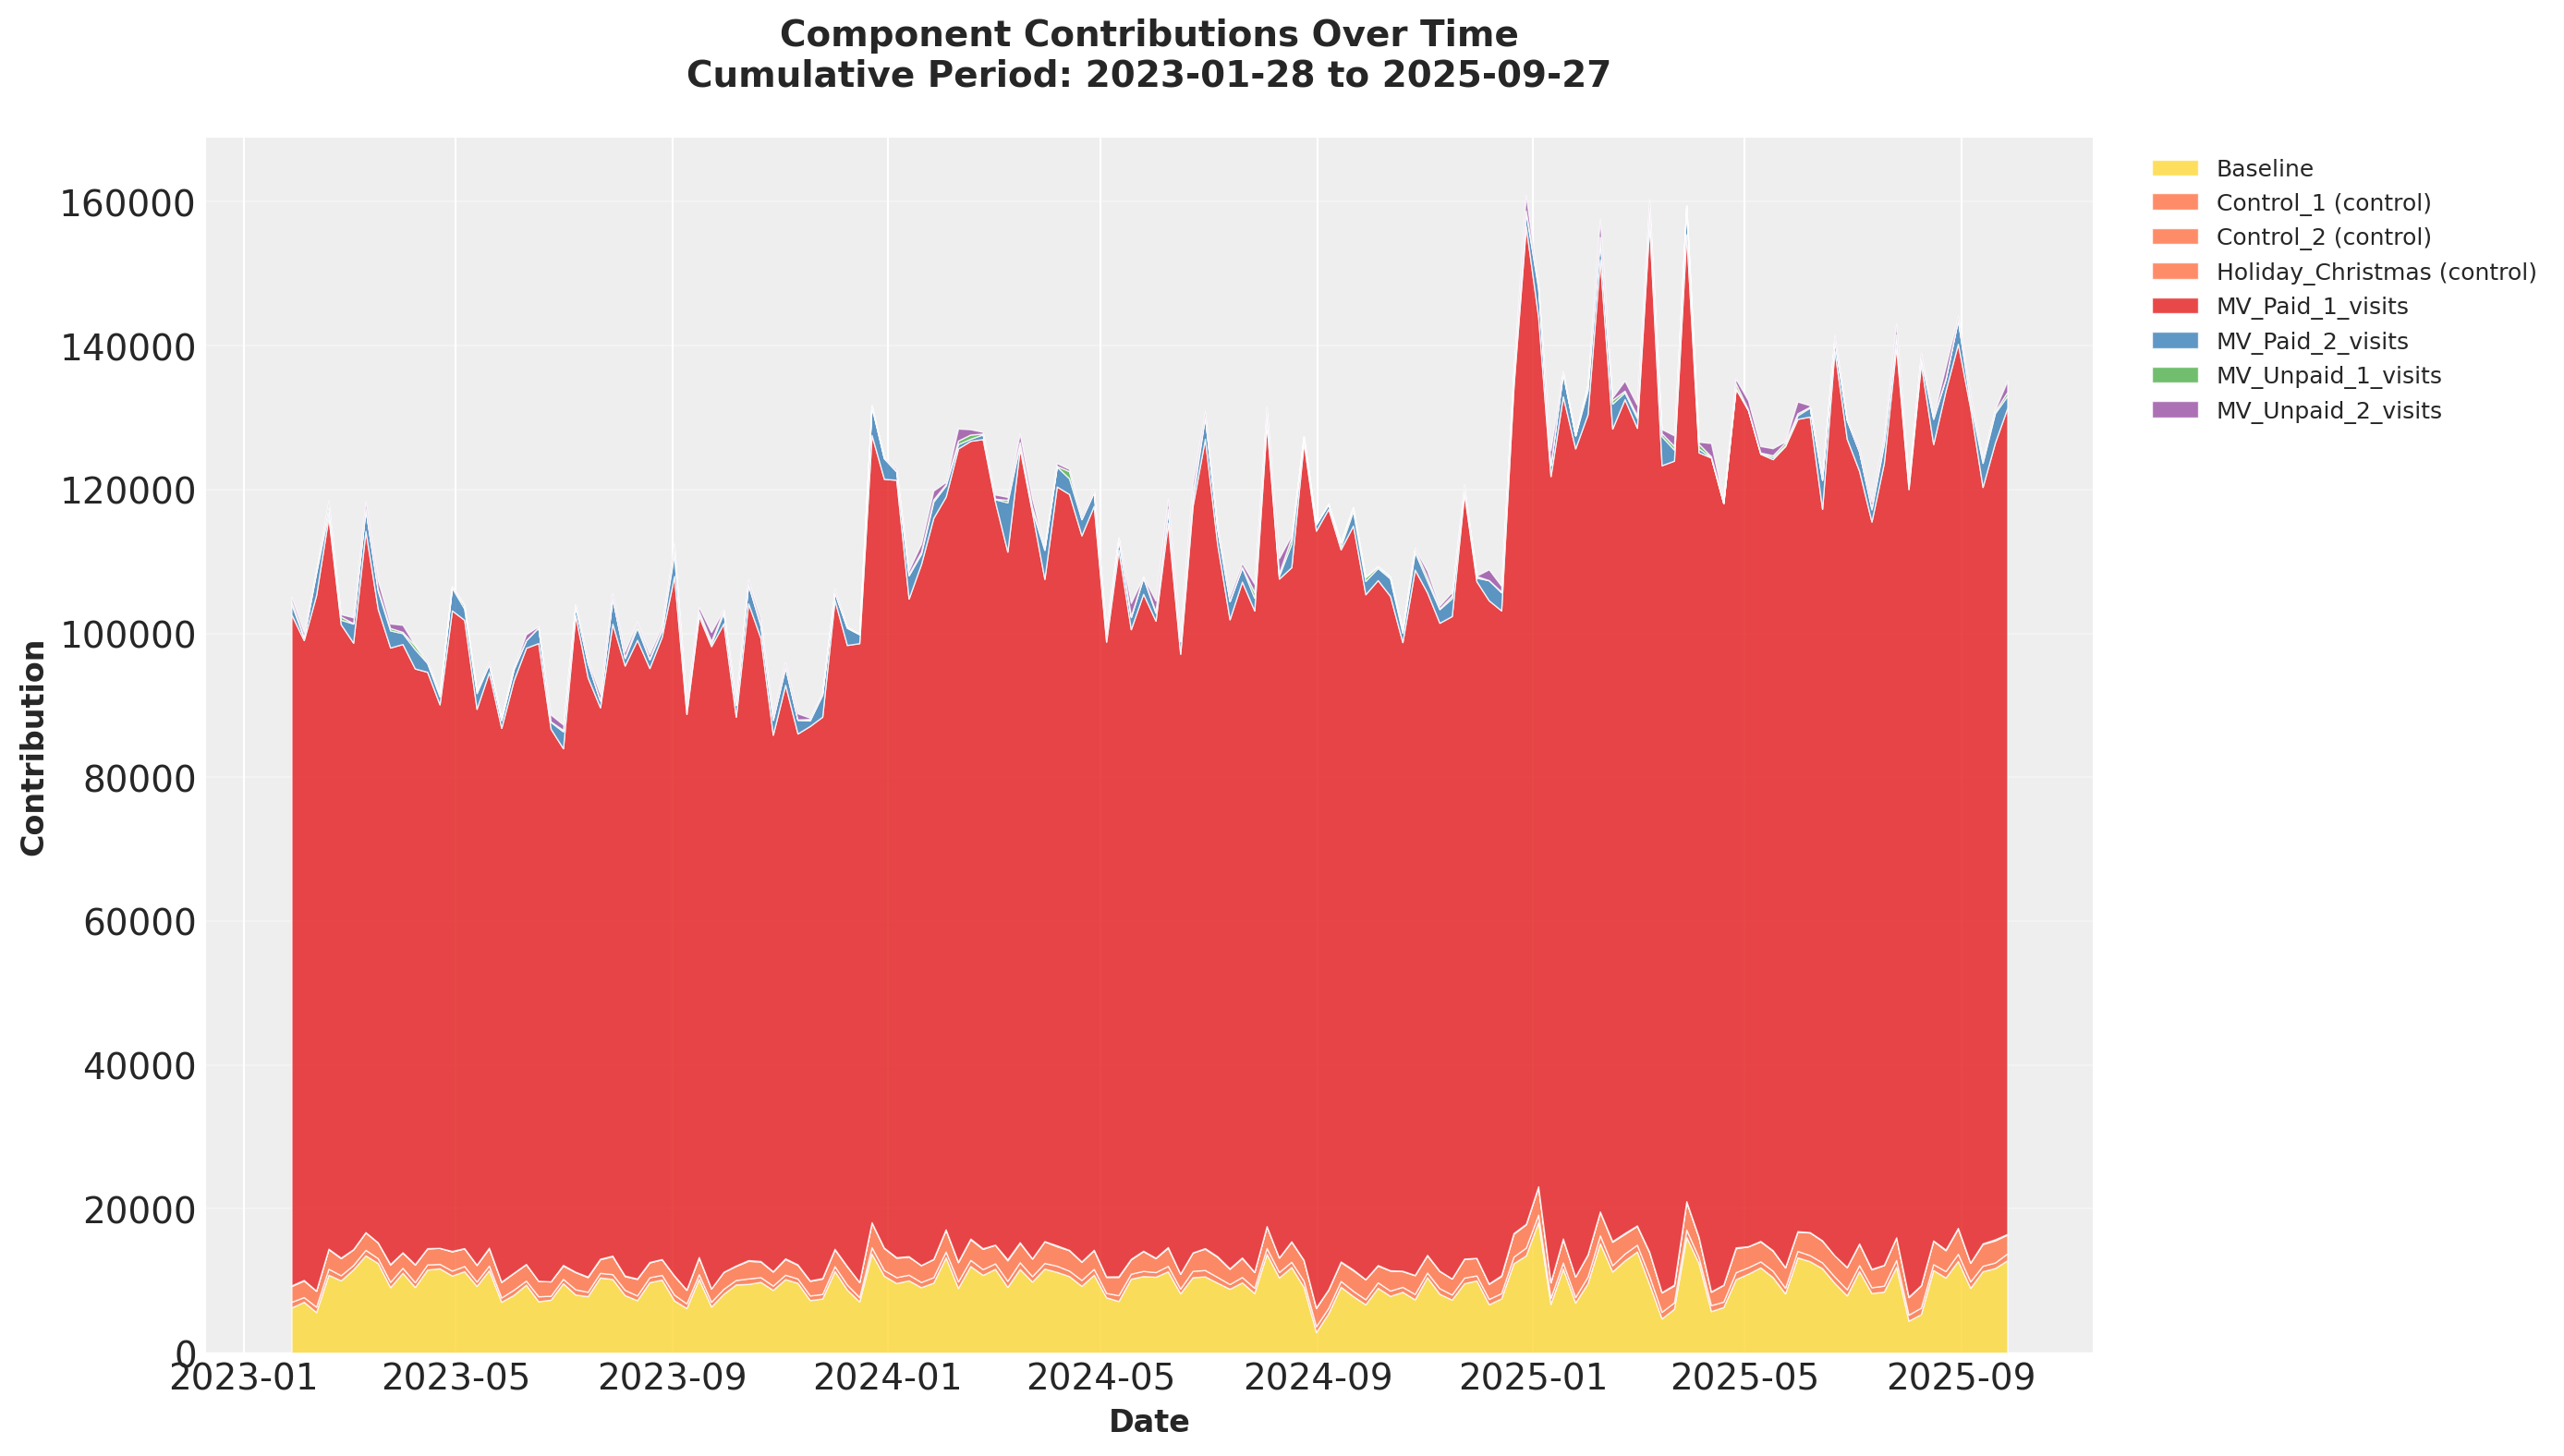

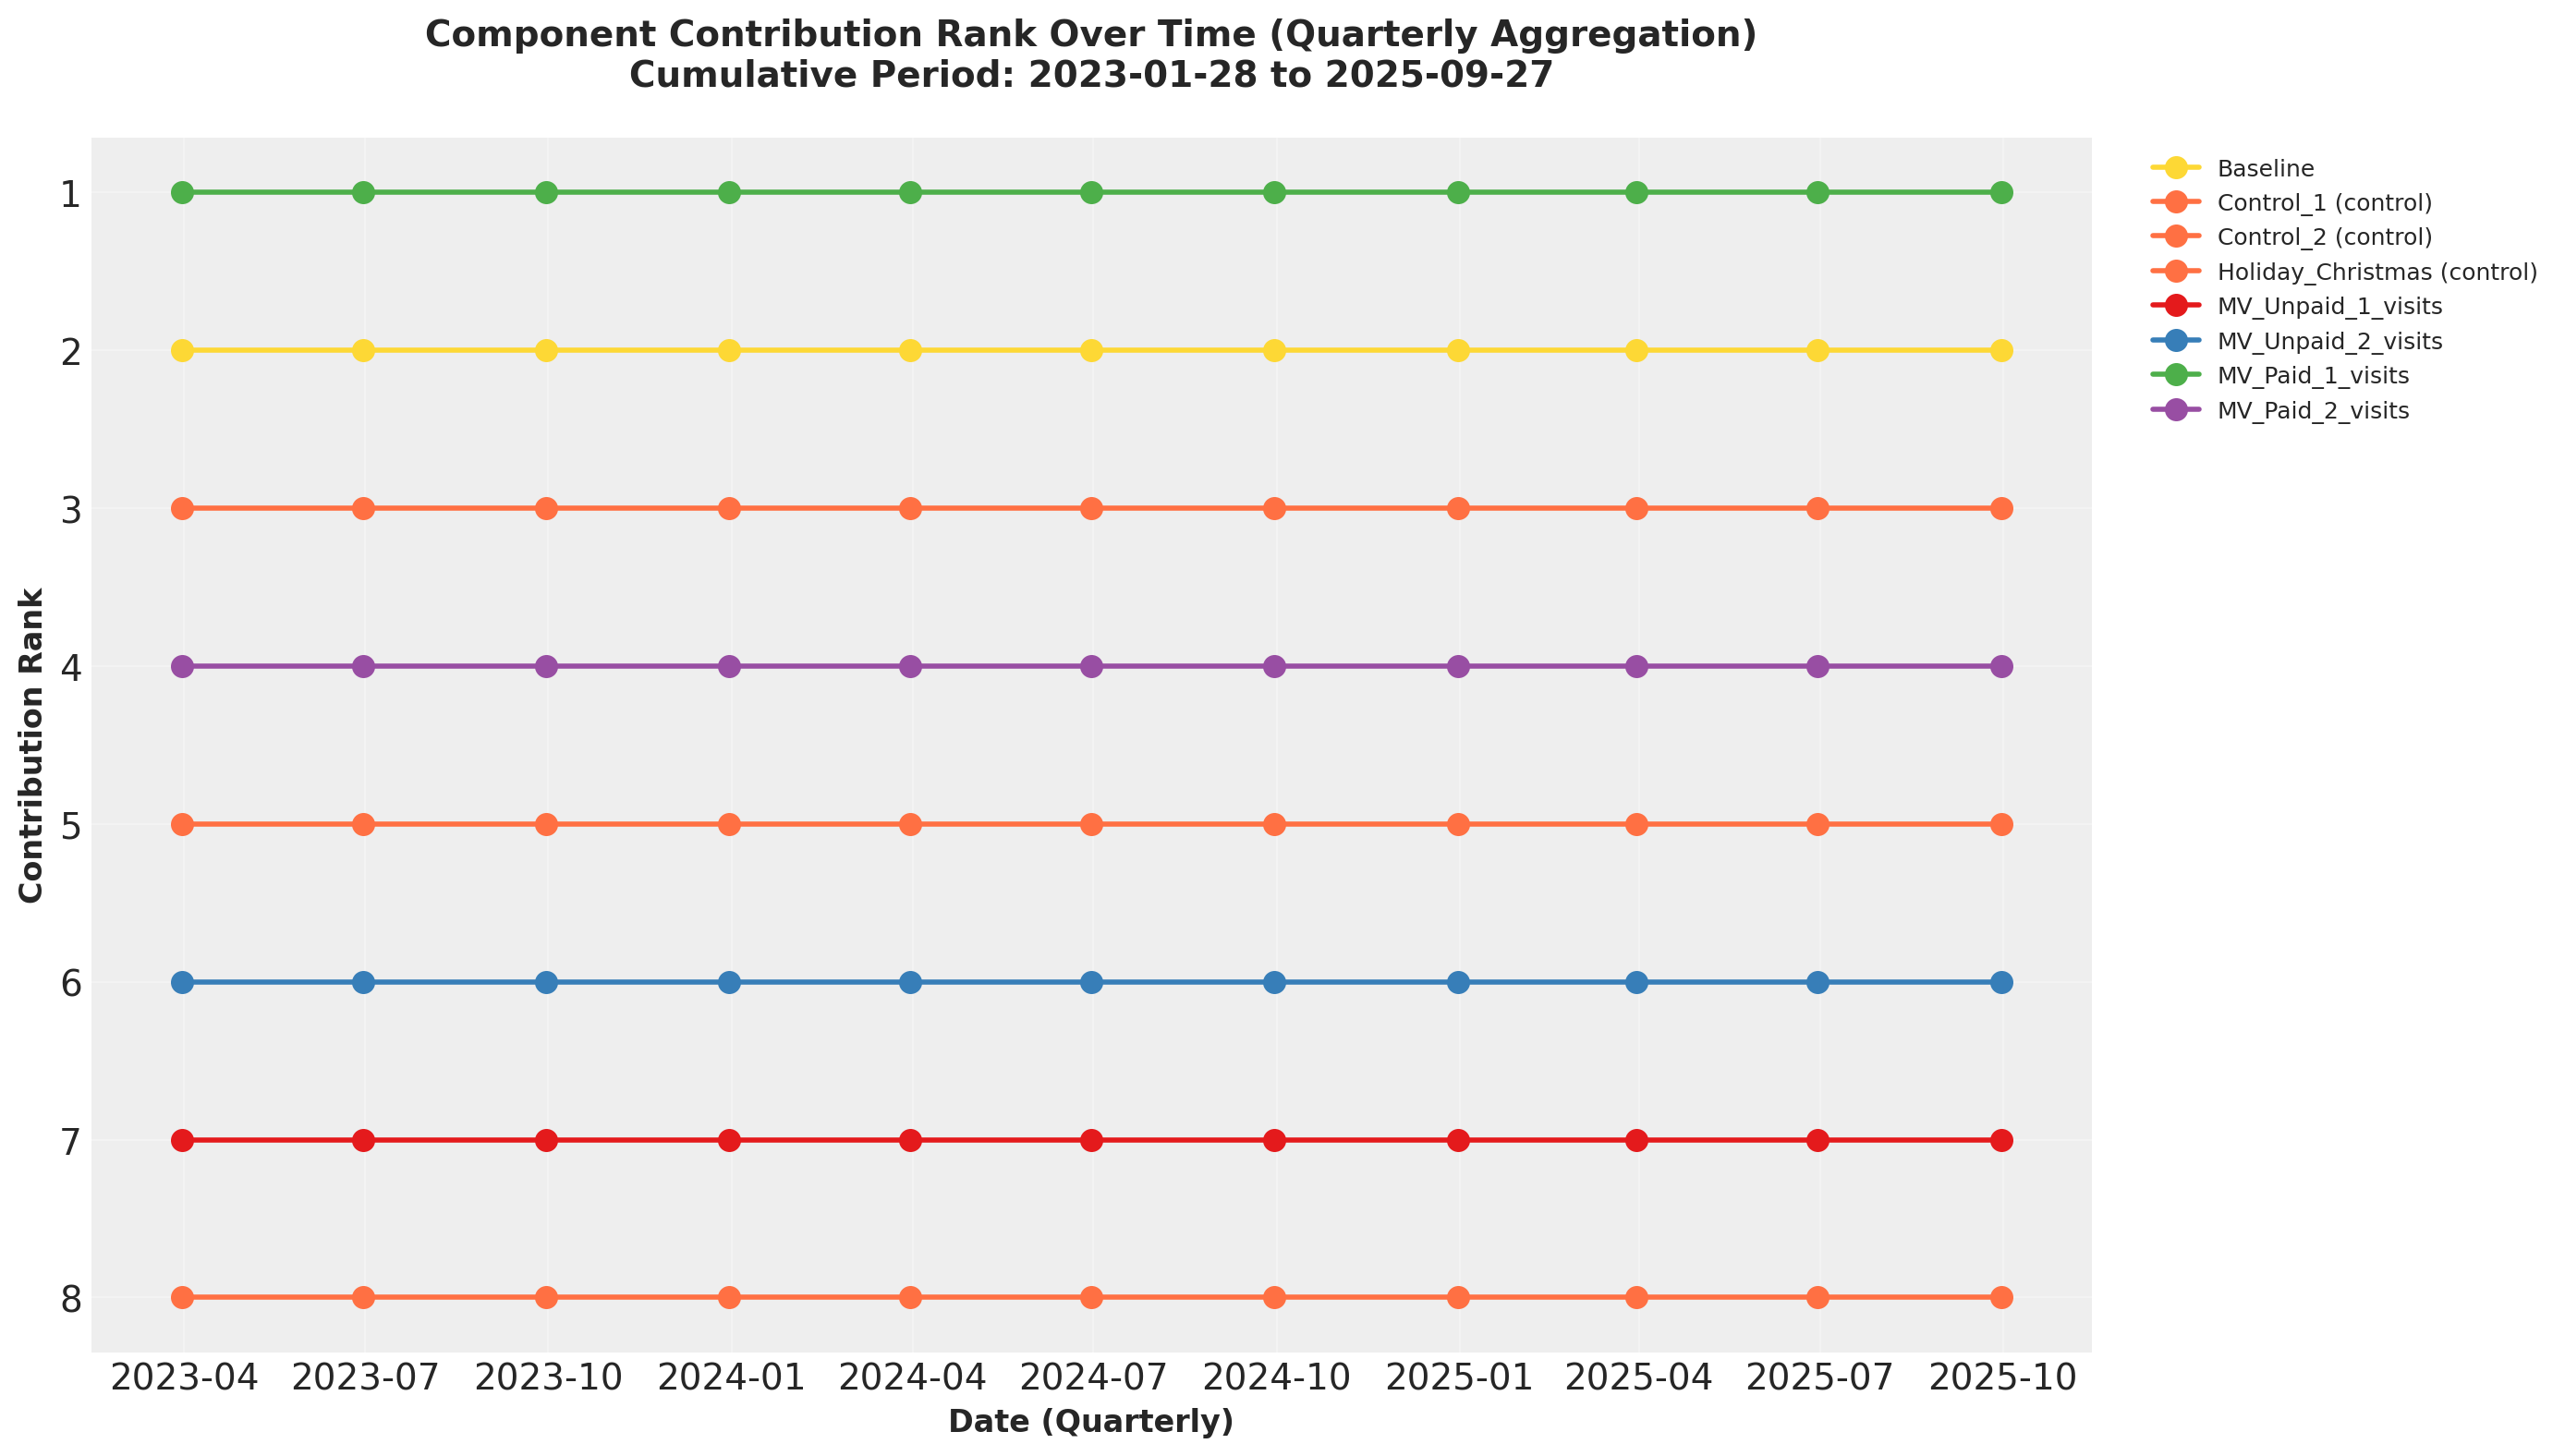

In [37]:
# Now returns 7 figures + aggregated contributions
fig1, fig2, fig3, fig4, fig5, fig6, fig7, agg_contrib = plot_roas_analysis(
    roas_results=roas_results_all,
    contributions=contributions,
    data=data,
    confidence_intervals=(0.85, 0.90),
    baseline_components = baseline_components
)

**Business use cases**

*Pros*

- Campaign-level evaluation: "What was the overall ROAS for Q4 2024?"
- Budget allocation decisions: "Which channel gave the best total return?"
- Executive reporting: Simple to communicate, single-number KPIs
- Period comparisons: Compare Q1 vs Q2 aggregate performance 

*Limitations*

- Hides temporal dynamics (seasonality, trends, diminishing returns)
- Can't identify when performance changed
- May mask optimization opportunities within the period
- No visibility into ROAS volatility/uncertainty



ROAS TIME SERIES RESULTS STRUCTURE

Channels processed: ['MV_Paid_1_visits', 'MV_Paid_2_visits']
Number of dates: 140
Date range: 2023-01-28T00:00:00.000000000 to 2025-09-27T00:00:00.000000000

MV_Paid_1_visits:
  ROAS array shape: (140, 140) (n_samples, n_dates)
  Number of posterior samples: 140
  Mean ROAS (over all periods): 38.7795
  Total spend: 420522.79

MV_Paid_2_visits:
  ROAS array shape: (140, 140) (n_samples, n_dates)
  Number of posterior samples: 140
  Mean ROAS (over all periods): 3.2104
  Total spend: 78413.29

GENERATING PLOTS...


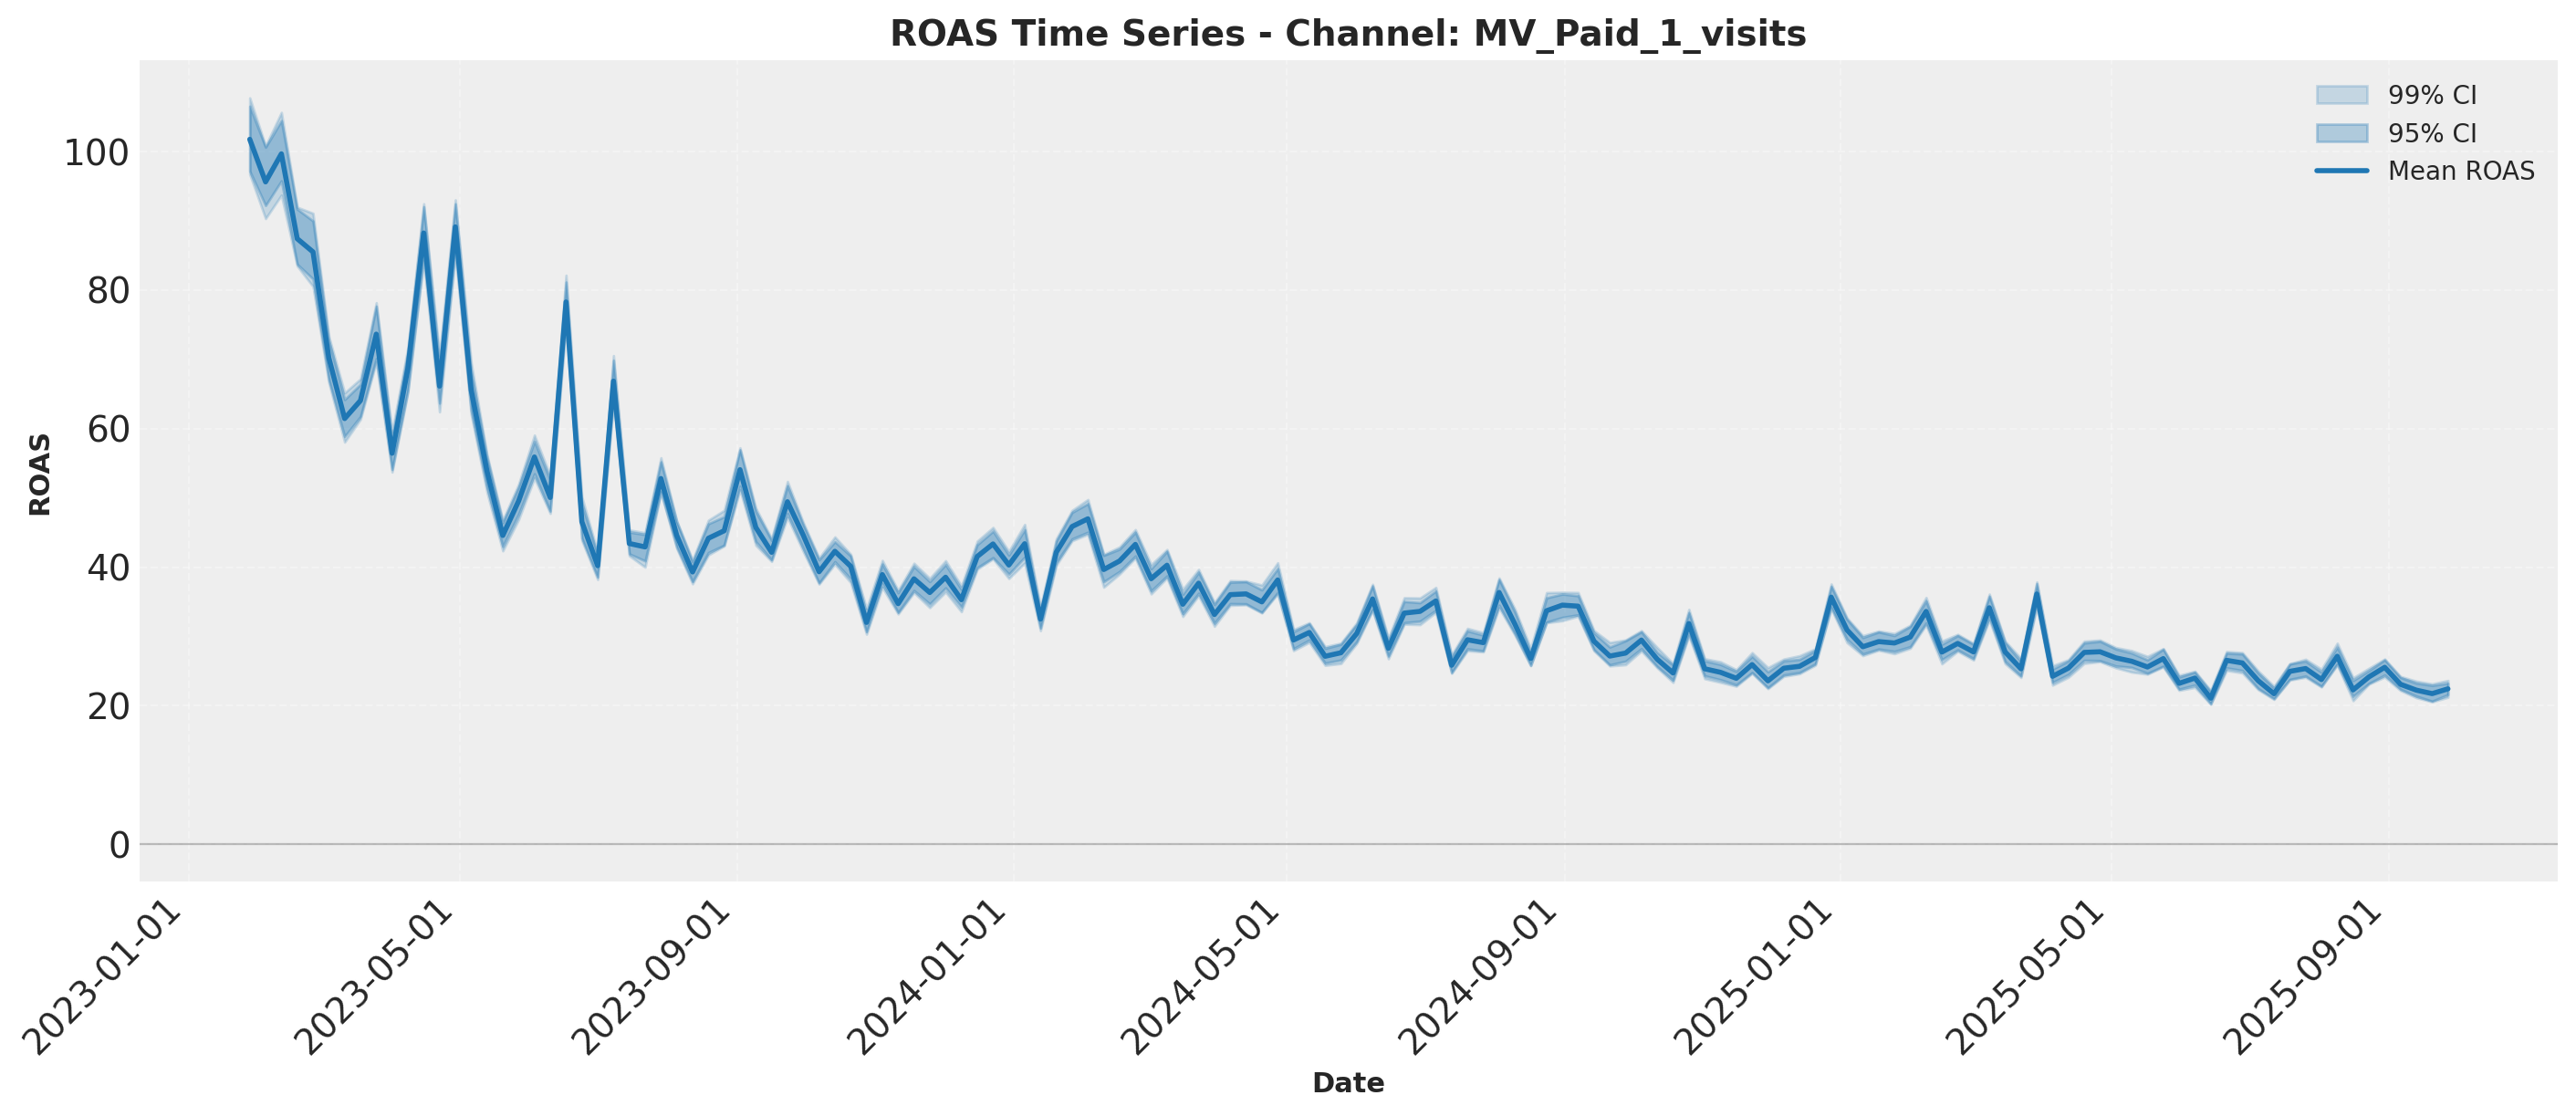

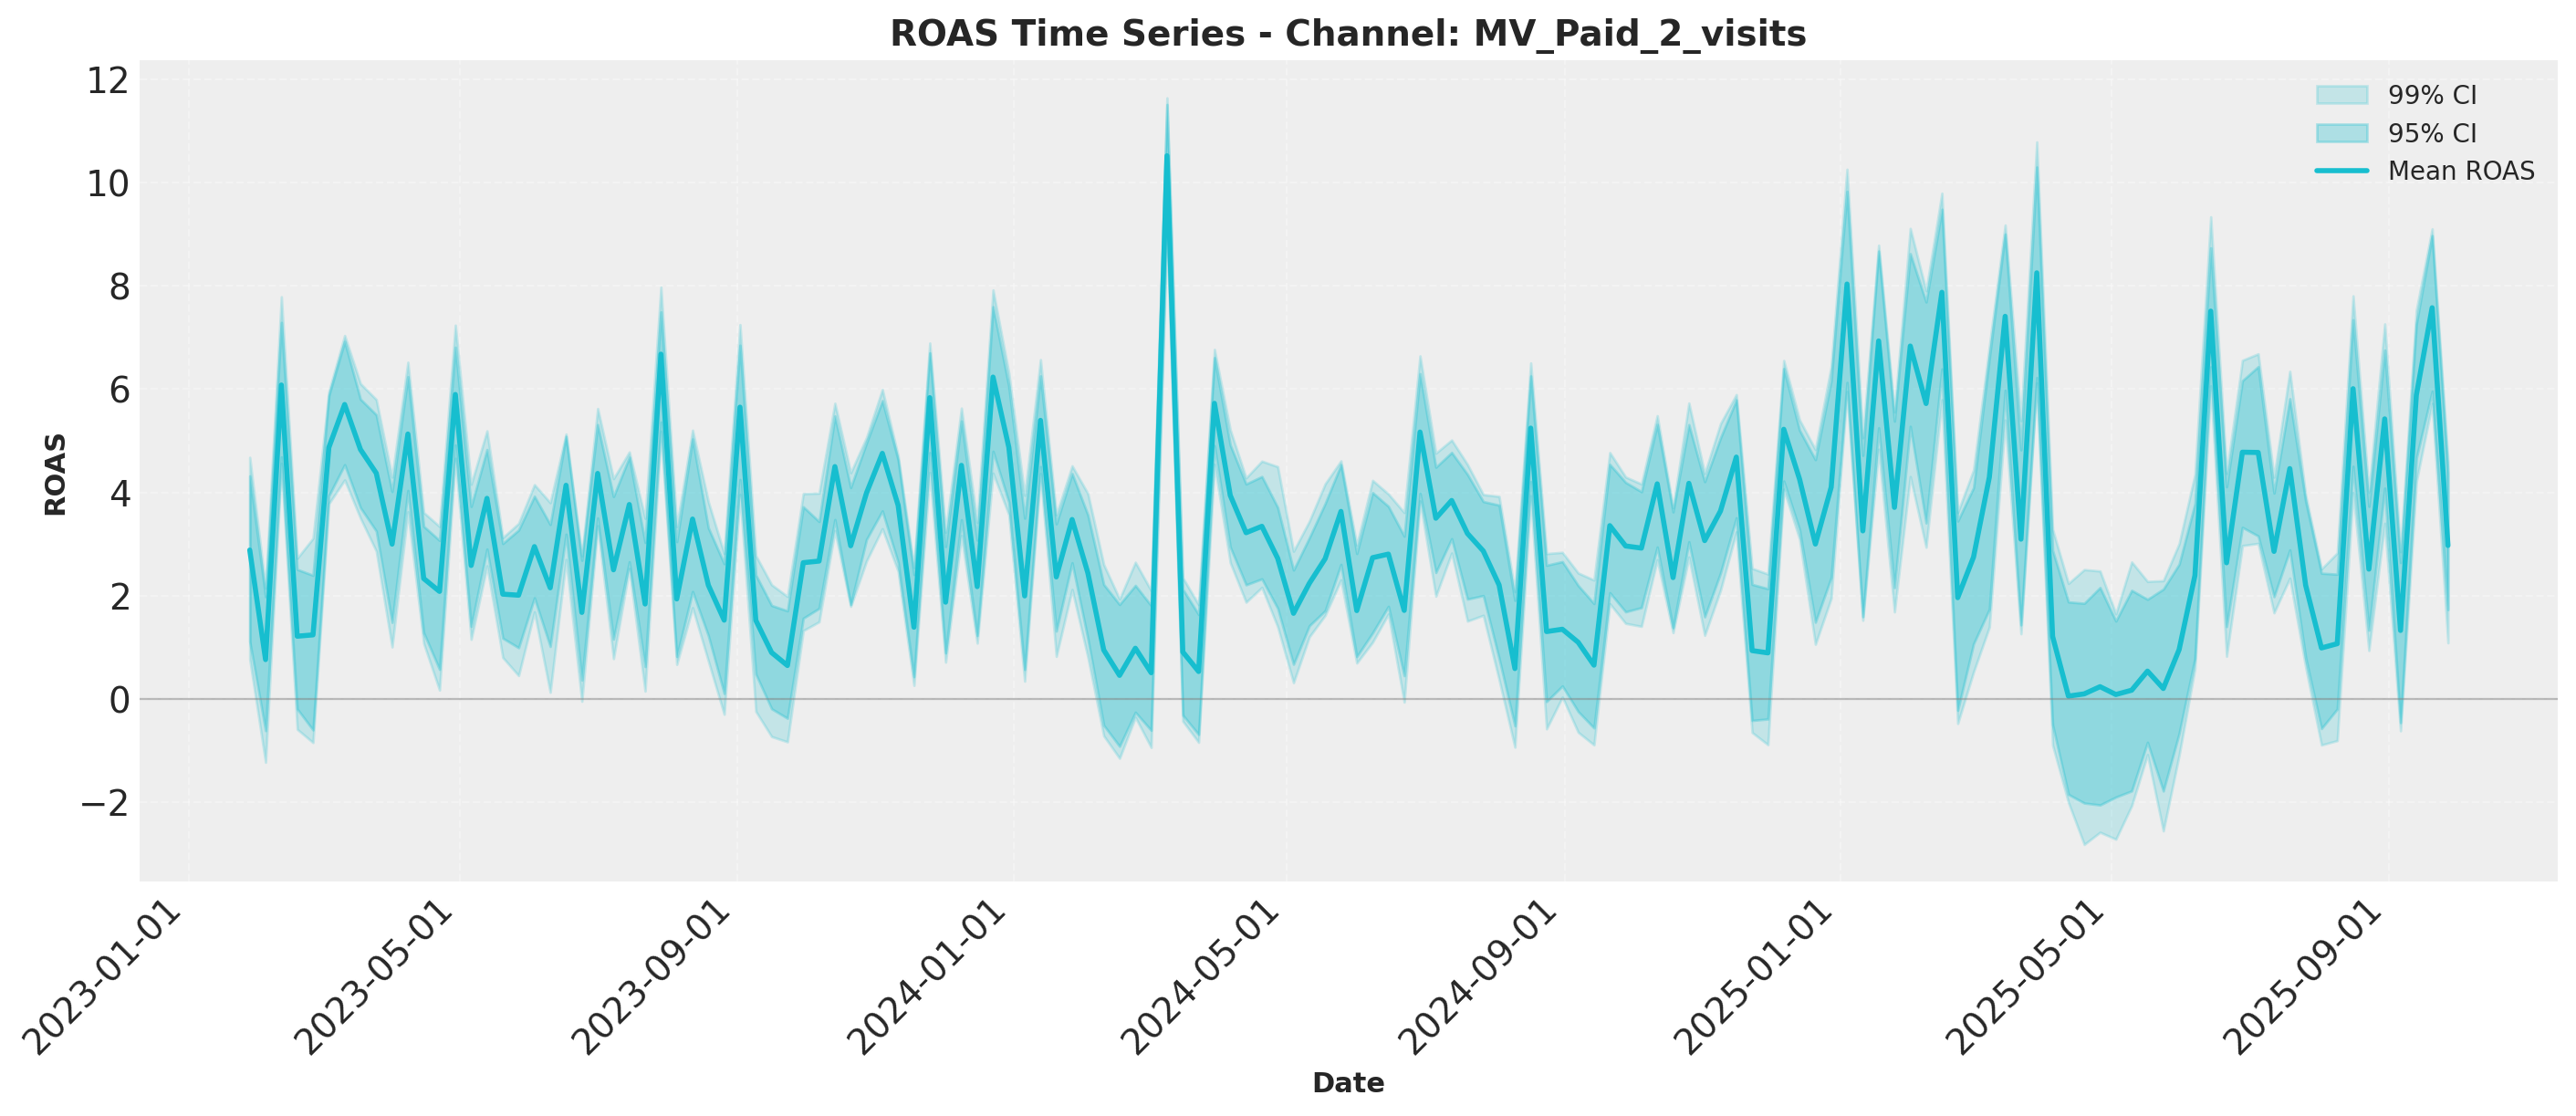


ROAS SUMMARY STATISTICS BY CHANNEL

MV_Paid_1_visits:
  Overall Mean ROAS: 38.7795
  Overall Median ROAS: 34.1285
  Overall Std Dev: 17.1094
  Overall 95% CI: [22.0793, 90.1407]
  Min Mean ROAS (across periods): 21.0955
  Max Mean ROAS (across periods): 101.7117

MV_Paid_2_visits:
  Overall Mean ROAS: 3.2104
  Overall Median ROAS: 2.9334
  Overall Std Dev: 2.1427
  Overall 95% CI: [-0.2533, 8.0146]
  Min Mean ROAS (across periods): 0.0541
  Max Mean ROAS (across periods): 10.5197


In [38]:
# =============================================================================
# TEST: ROAS Time Series Calculation and Visualization
# =============================================================================

# Step 1: Calculate ROAS time series with all posterior samples

roas_ts_results = calculate_roas_time_series(
    contributions=contributions,
    data=data,
    channel_cols=paid_channel_names,  # Only paid channels
    target_column='y',
    spend_mapping=spend_mapping  # Pass the spend mapping
)

# Step 2: Inspect the results structure
print("\n" + "="*80)
print("ROAS TIME SERIES RESULTS STRUCTURE")
print("="*80)
print(f"\nChannels processed: {roas_ts_results['channel_cols']}")
print(f"Number of dates: {len(roas_ts_results['dates'])}")
print(f"Date range: {roas_ts_results['dates'][0]} to {roas_ts_results['dates'][-1]}")

for channel in roas_ts_results['channel_cols']:
    roas_samples = roas_ts_results['roas_time_series'][channel]
    print(f"\n{channel}:")
    print(f"  ROAS array shape: {roas_samples.shape} (n_samples, n_dates)")
    print(f"  Number of posterior samples: {roas_samples.shape[0]}")
    print(f"  Mean ROAS (over all periods): {np.nanmean(roas_samples):.4f}")
    print(f"  Total spend: {roas_ts_results['spend'][channel].sum():.2f}")

# Step 3: Visualize ROAS time series
print("\n" + "="*80)
print("GENERATING PLOTS...")
print("="*80)

# Example 1: Using default confidence levels (95%, 99%)
plot_results = plot_roas_time_series(
    roas_results=roas_ts_results,
    confidence_levels=(0.95, 0.99),
    show_mean_line=True,
    date_range=None,  # Show all dates
    figsize=(14, 6)
)

# Example 2: Using custom confidence levels (90%, 95%)
# plot_results = plot_roas_time_series(
#     roas_results=roas_ts_results,
#     confidence_levels=(0.90, 0.95),
#     show_mean_line=True,
#     date_range=None,
#     figsize=(14, 6)
# )

# # Example 3: Using date range filter
# plot_results = plot_roas_time_series(
#     roas_results=roas_ts_results,
#     confidence_levels=(0.90, 0.95),
#     show_mean_line=True,
#     date_range=(pd.Timestamp('2021-02-01'), pd.Timestamp('2021-07-30')),
#     figsize=(14, 6)
# )

# Display the plots
plt.show()

# Step 4: Print some summary statistics
print("\n" + "="*80)
print("ROAS SUMMARY STATISTICS BY CHANNEL")
print("="*80)

for channel in roas_ts_results['channel_cols']:
    roas_samples = roas_ts_results['roas_time_series'][channel]
    
    # Calculate mean ROAS per time period
    mean_roas_per_period = np.nanmean(roas_samples, axis=0)
    
    # Calculate overall statistics
    overall_mean = np.nanmean(roas_samples)
    overall_median = np.nanmedian(roas_samples)
    overall_std = np.nanstd(roas_samples)
    
    # Calculate 95% CI for overall ROAS
    ci_95_lower = np.nanpercentile(roas_samples, 2.5)
    ci_95_upper = np.nanpercentile(roas_samples, 97.5)
    
    print(f"\n{channel}:")
    print(f"  Overall Mean ROAS: {overall_mean:.4f}")
    print(f"  Overall Median ROAS: {overall_median:.4f}")
    print(f"  Overall Std Dev: {overall_std:.4f}")
    print(f"  Overall 95% CI: [{ci_95_lower:.4f}, {ci_95_upper:.4f}]")
    print(f"  Min Mean ROAS (across periods): {np.nanmin(mean_roas_per_period):.4f}")
    print(f"  Max Mean ROAS (across periods): {np.nanmax(mean_roas_per_period):.4f}")

**Business usecase**

*Pros*

- Trend analysis: "Is our ROAS improving or declining over time in a specific channel?"
- Seasonality detection: "When during the year does this channel perform best?"
- Tactical optimization: "Should we increase spend this week in this channel based on recent ROAS?"
- Event impact analysis: "Did the campaign launch improved ROAS?"

*Limitations*

- More complex to explain to stakeholders
- Individual period ROAS can be noisy
- Requires more sophisticated visualization
- May show high variance in low-spend periods


In [39]:
# Calculate mROAS 
mroas_results = calculate_marginal_roas(
    mmm=mmm,
    data=data,
    config=config,
    # prediction_days=30,
    marginal_increase=0.01 , # 1% increase
    random_seed=seed
)


2026-01-04 22:53:16,539 - b2b_src.contributions - INFO - Analyzing marginal ROAS for 2 paid channel(s): MV_Paid_1_visits, MV_Paid_2_visits
2026-01-04 22:53:16,541 - b2b_src.contributions - INFO - Generating baseline predictions...
Sampling: [y]
2026-01-04 22:53:16,566 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:53:16,732 - b2b_src.contributions - INFO - ✓ Detected log-transformed target - applying exp() transformation
2026-01-04 22:53:16,733 - b2b_src.contributions - INFO - ✓ Applying target_scale: 1.0
2026-01-04 22:53:16,734 - b2b_src.contributions - INFO - Calculating mROAS for channel 1/2: MV_Paid_1_visits...
Sampling: [y]
2026-01-04 22:53:16,805 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:53:31,885 - b2b_src.contributions - INFO - Calculating mROAS for channel 2/2: MV_Paid_2_visits...
Sampling: [y]
2026-01-04 22:53:31,959 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [40]:
mroas_results

{'mroas': {'MV_Paid_1_visits': np.float64(39.50085542344086),
  'MV_Paid_2_visits': np.float64(6.797843903413168)},
 'mroas_samples': {'MV_Paid_1_visits': array([39.50085542]),
  'MV_Paid_2_visits': array([6.7978439])},
 'incremental_sales': {'MV_Paid_1_visits': np.float64(166110.10118413964),
  'MV_Paid_2_visits': np.float64(5330.41314110205)},
 'incremental_sales_samples': {'MV_Paid_1_visits': array([166110.10118414]),
  'MV_Paid_2_visits': array([5330.4131411])},
 'incremental_spend': {'MV_Paid_1_visits': np.float64(4205.227947685545),
  'MV_Paid_2_visits': np.float64(784.1329128528051)},
 'period': {'start': np.int64(0), 'end': np.int64(139)},
 'cumulative_period': {'start_date': Timestamp('1970-01-01 00:00:00'),
  'end_date': Timestamp('1970-01-01 00:00:00.000000139'),
  'days': 140},
 'marginal_increase': 0.01}

In [41]:
results = analyze_revenue_vs_spend_levels(
         mmm=mmm,
         data=data,
         config=config,
         random_seed=327
     )

2026-01-04 22:53:46,912 - b2b_src.contributions - INFO - Found 2 paid channels to analyze
2026-01-04 22:53:46,912 - b2b_src.contributions - INFO - Paid channels: ['MV_Paid_1_visits', 'MV_Paid_2_visits']
2026-01-04 22:53:46,913 - b2b_src.contributions - INFO - 
Analysis period: 140 observations
2026-01-04 22:53:46,914 - b2b_src.contributions - INFO - 
Generating baseline predictions (1.0x spend)...
Sampling: [y]
2026-01-04 22:53:46,937 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:53:47,107 - b2b_src.contributions - INFO - ✓ Detected log-transformed target - applying exp() transformation
2026-01-04 22:53:47,108 - b2b_src.contributions - INFO - ✓ Applying target_scale: 1.0
2026-01-04 22:53:47,108 - b2b_src.contributions - INFO - ✓ Baseline total revenue: $16,156,256.91
2026-01-04 22:53:47,109 - b2b_src.contributions - INFO - 
2026-01-04 22:53:47,109 - b2b_src.contributions - INFO - Analyzing channel 1/2: MV_Paid_1_visits
2026-01-04 22:53:47,109 - b2b_src.contributions - INFO - ======================================================================
2026-01-04 22:53:47,110 - b2b_src.contributions - INFO -   Simulating multiplier 1/9: 0.2x...
Sampling: [y]
2026-01-04 22:53:47,185 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:54:02,113 - b2b_src.contributions - INFO -   Simulating multiplier 2/9: 0.4x...
Sampling: [y]
2026-01-04 22:54:02,184 - pymc.sampling.forward - INFO - Sampling: [y]


...

2026-01-04 22:57:17,952 - b2b_src.contributions - INFO -   Simulating multiplier 8/9: 4.0x...
Sampling: [y]
2026-01-04 22:57:18,026 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:57:33,038 - b2b_src.contributions - INFO -   Simulating multiplier 9/9: 5.0x...
Sampling: [y]
2026-01-04 22:57:33,118 - pymc.sampling.forward - INFO - Sampling: [y]


c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\mmmenv\Lib\site-packages\rich\live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-01-04 22:57:48,021 - b2b_src.contributions - INFO - 
2026-01-04 22:57:48,022 - b2b_src.contributions - INFO - Analysis complete!
2026-01-04 22:57:48,022 - b2b_src.contributions - INFO - ======================================================================



c:\Users\David Rodriguez\Desktop\Developer\4M Project\pymc_marketing\b2b_src\visual_tools.py:1900: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


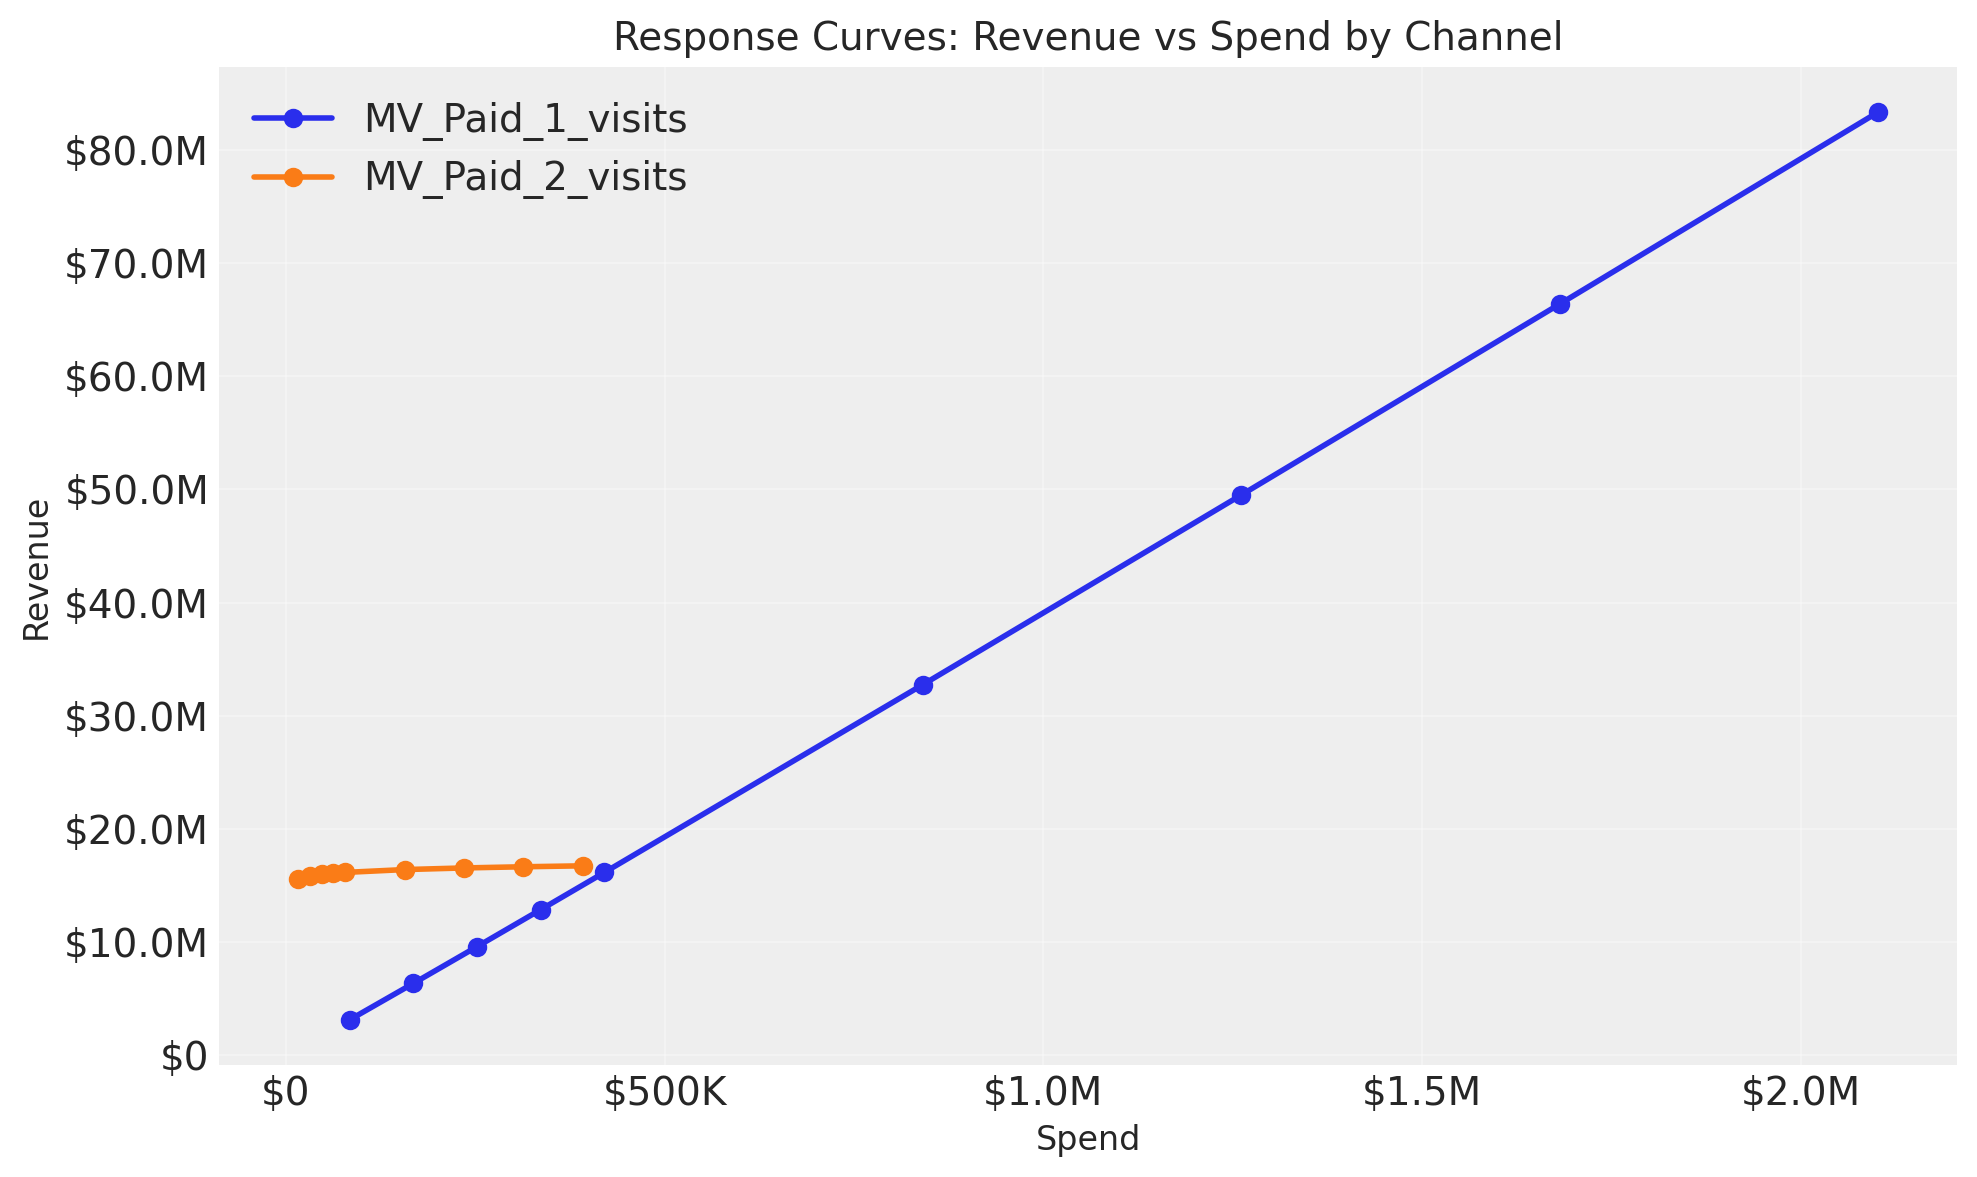

In [42]:

fig, ax = plot_response_curves(results)
plt.show()